In [1]:

!pip install -q gdown

import gdown
import os

# Folder to save the downloaded files
output_dir = "/kaggle/working/prepared_data"
os.makedirs(output_dir, exist_ok=True)

# Google Drive file IDs
files = {
    "validation.npy": "1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF",
    "validation_labels.npy": "12aNe7CAD2BcuR6SMw67fgW5YbHUtFuB7",
    "train.npy": "1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK",
    "train_labels.npy": "1YBjDvRMNJzlt7QML6VYINLTGMQnpNgsU",
    "test.npy": "1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9",
    "test_labels.npy": "1LCrW9VOk9UuyyMAr2C4MOSjMNbX6u__U"
}

# Download all files
for filename, file_id in files.items():
    output_path = os.path.join(output_dir, filename)

    print(f"\nDownloading {filename}...")

    result = gdown.download(
        id=file_id,
        output=output_path,
        quiet=False
    )

    if result is None or not os.path.exists(output_path):
        print(f"FAILED: {filename}")
    else:
        print(f"SUCCESS: {filename}")

print("\nDownload process finished!")


Downloading...
From (original): https://drive.google.com/uc?id=1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF
From (redirected): https://drive.google.com/uc?id=1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF&confirm=t&uuid=f430c0b8-0a72-4a22-b4c3-90abb90e12fe
To: /kaggle/working/prepared_data/validation.npy
100%|██████████| 174M/174M [00:01<00:00, 90.3MB/s] 


SUCCESS: validation.npy



Downloading...
From: https://drive.google.com/uc?id=12aNe7CAD2BcuR6SMw67fgW5YbHUtFuB7
To: /kaggle/working/prepared_data/validation_labels.npy
100%|██████████| 28.4k/28.4k [00:00<00:00, 24.6MB/s]


SUCCESS: validation_labels.npy



Downloading...
From (original): https://drive.google.com/uc?id=1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK
From (redirected): https://drive.google.com/uc?id=1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK&confirm=t&uuid=8411507d-758e-4b7b-8929-4d92aa52be84
To: /kaggle/working/prepared_data/train.npy
100%|██████████| 810M/810M [00:05<00:00, 136MB/s]  


SUCCESS: train.npy



... (2 outputs left out)

Downloading...
From (original): https://drive.google.com/uc?id=1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9
From (redirected): https://drive.google.com/uc?id=1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9&confirm=t&uuid=5f92ebc6-fd4f-4a4a-a257-91a63e0a52fa
To: /kaggle/working/prepared_data/test.npy
100%|██████████| 174M/174M [00:01<00:00, 108MB/s]  


SUCCESS: test.npy



Downloading...
From: https://drive.google.com/uc?id=1LCrW9VOk9UuyyMAr2C4MOSjMNbX6u__U
To: /kaggle/working/prepared_data/test_labels.npy
100%|██████████| 28.4k/28.4k [00:00<00:00, 30.0MB/s]

SUCCESS: test_labels.npy

Download process finished!


In [2]:

import os

for filename in sorted(os.listdir(output_dir)):
    path = os.path.join(output_dir, filename)
    size_mb = os.path.getsize(path) / (1024 ** 2)
    print(f"{filename}: {size_mb:.2f} MB")


test.npy: 165.66 MB
test_labels.npy: 0.03 MB
train.npy: 772.83 MB
train_labels.npy: 0.13 MB
validation.npy: 165.61 MB
validation_labels.npy: 0.03 MB


In [4]:

import numpy as np

X_train = np.load(os.path.join(output_dir, "train.npy"), mmap_mode="r")
y_train = np.load(os.path.join(output_dir, "train_labels.npy"))

X_val = np.load(os.path.join(output_dir, "validation.npy"), mmap_mode="r")
y_val = np.load(os.path.join(output_dir, "validation_labels.npy"))

X_test = np.load(os.path.join(output_dir, "test.npy"), mmap_mode="r")
y_test = np.load(os.path.join(output_dir, "test_labels.npy"))

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (16487, 128, 128, 3) (16487,)
Validation: (3533, 128, 128, 3) (3533,)
Test: (3534, 128, 128, 3) (3534,)


In [5]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [30]:
import numpy as np

split_labels = {
    "train": np.asarray(y_train).reshape(-1),
    "validation": np.asarray(y_val).reshape(-1),
    "test": np.asarray(y_test).reshape(-1),
}

for split_name, labels in split_labels.items():
    class_ids, counts = np.unique(labels, return_counts=True)

    print(f"\n{split_name}:")
    print(f"عدد الصور: {len(labels)}")
    print(f"الفئات الموجودة: {class_ids.tolist()}")
    print("عدد الصور لكل فئة:")
    for class_id, count in zip(class_ids, counts):
        print(f"  الفئة {class_id}: {count}")


train:
عدد الصور: 16487
الفئات الموجودة: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
عدد الصور لكل فئة:
  الفئة 0: 1122
  الفئة 1: 839
  الفئة 2: 2095
  الفئة 3: 1258
  الفئة 4: 3368
  الفئة 5: 726
  الفئة 6: 1818
  الفئة 7: 963
  الفئة 8: 3038
  الفئة 9: 1260

validation:
عدد الصور: 3533
الفئات الموجودة: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
عدد الصور لكل فئة:
  الفئة 0: 240
  الفئة 1: 180
  الفئة 2: 449
  الفئة 3: 269
  الفئة 4: 721
  الفئة 5: 156
  الفئة 6: 390
  الفئة 7: 207
  الفئة 8: 651
  الفئة 9: 270

test:
عدد الصور: 3534
الفئات الموجودة: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
عدد الصور لكل فئة:
  الفئة 0: 241
  الفئة 1: 180
  الفئة 2: 449
  الفئة 3: 270
  الفئة 4: 722
  الفئة 5: 155
  الفئة 6: 390
  الفئة 7: 206
  الفئة 8: 651
  الفئة 9: 270


In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models


def build_cnn(input_shape=(128, 128, 3), num_classes=10):
    """Build a baseline CNN for 10-class animal image classification."""
    inputs = layers.Input(shape=input_shape)

    # Block 1: 32 filters
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2: 64 filters
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3: 128 filters
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="baseline_cnn")
    return model


if __name__ == "__main__":
    model = build_cnn(input_shape=(128, 128, 3), num_classes=10)
    model.summary()

    # Pass a single dummy RGB image (batch size = 1) to verify output shape and probabilities
    sample_image = np.random.rand(1, 128, 128, 3).astype(np.float32)
    predictions = model(sample_image, training=False).numpy()

    print("Sample output shape:", predictions.shape)  # Expected: (1, 10)
    print("Probabilities sum:", float(np.sum(predictions[0])))  # Expected: ~1.0
    print("Sample probabilities:", predictions[0])

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

Sample output shape: (1, 10)
Probabilities sum: 0.9999999403953552
Sample probabilities: [0.09000397 0.09299593 0.09784569 0.09680308 0.11533036 0.09707123
 0.10234305 0.11142802 0.09108049 0.10509812]


In [7]:

model = build_cnn(
    input_shape=(128, 128, 3),
    num_classes=10
)

model.summary()

# Test with a dummy image
sample_image = np.random.rand(
    1, 128, 128, 3
).astype(np.float32)

predictions = model(sample_image, training=False).numpy()

print("Output shape:", predictions.shape)
print("Probabilities sum:", np.sum(predictions[0]))
print("Probabilities:", predictions[0])


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

Output shape: (1, 10)
Probabilities sum: 1.0
Probabilities: [0.11206901 0.09894892 0.10179779 0.09635212 0.07413122 0.12572855
 0.10618412 0.09537379 0.08382171 0.10559279]


In [9]:

model = compile_model(model)


Model compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metrics: Accuracy


In [8]:

import tensorflow as tf
from tensorflow.keras.optimizers import Adam

def compile_model(model):
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("Model compiled successfully!")
    print("Optimizer: Adam")
    print("Loss: Sparse Categorical Crossentropy")
    print("Metrics: Accuracy")

    return model


In [10]:
from pathlib import Path

import numpy as np
import tensorflow as tf

INPUT_SHAPE = (128, 128, 3)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 10
PIXEL_SCALE = None  # Set to 1 for [0, 1] pixels or 255 for [0, 255] pixels.
SPLITS = ("train", "validation", "test")
MODEL_PATH = Path("/kaggle/working/models/animals10_baseline_cnn.keras")

required = {
    name for split in SPLITS
    for name in (f"{split}.npy", f"{split}_labels.npy")
}
candidates = [Path("/kaggle/working/prepared_data")]
candidates.extend(
    path.parent for path in Path("/kaggle/input").rglob("train.npy")
)
data_dir = next(
    (path for path in candidates if all((path / name).is_file() for name in required)),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Attach a Kaggle dataset containing all six NPY files in one folder.")

print("Dataset:", data_dir)
print("GPU:", tf.config.list_physical_devices("GPU"))

Dataset: /kaggle/working/prepared_data
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [11]:
%pip install -q gdown

from pathlib import Path
import gdown

output_dir = Path("/kaggle/working/prepared_data")
output_dir.mkdir(parents=True, exist_ok=True)

files = {
    "train.npy": "1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK",
    "train_labels.npy": "1YBjDvRMNJzlt7QML6VYINLTGMQnpNgsU",
    "validation.npy": "1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF",
    "validation_labels.npy": "12aNe7CAD2BcuR6SMw67fgW5YbHUtFuB7",
    "test.npy": "1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9",
    "test_labels.npy": "1LCrW9VOk9UuyyMAr2C4MOSjMNbX6u__U",
}

for filename, file_id in files.items():
    output_path = output_dir / filename
    print(f"\nDownloading {filename}...")

    result = gdown.download(id=file_id, output=str(output_path), quiet=False)
    if result is None or not output_path.is_file() or output_path.stat().st_size == 0:
        raise RuntimeError(f"Download failed: {filename}")

    print(f"SUCCESS: {filename}")

print(f"\nAll 6 files downloaded to {output_dir}")

Note: you may need to restart the kernel to use updated packages.



Downloading...
From (original): https://drive.google.com/uc?id=1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK
From (redirected): https://drive.google.com/uc?id=1w1GxSpmeEebsTIDWlGiS_HXC23ZpJLOK&confirm=t&uuid=7662dc90-aeab-4ab9-b3a3-5bd6bddeb937
To: /kaggle/working/prepared_data/train.npy
100%|██████████| 810M/810M [00:04<00:00, 166MB/s]  


SUCCESS: train.npy



Downloading...
From: https://drive.google.com/uc?id=1YBjDvRMNJzlt7QML6VYINLTGMQnpNgsU
To: /kaggle/working/prepared_data/train_labels.npy
100%|██████████| 132k/132k [00:00<00:00, 73.7MB/s]


SUCCESS: train_labels.npy



Downloading...
From (original): https://drive.google.com/uc?id=1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF
From (redirected): https://drive.google.com/uc?id=1C4oC5MtjUUrWj0WGH0iagv5A8nkKXkZF&confirm=t&uuid=e2abe11d-5472-4f2e-80cc-05c92dbd0447
To: /kaggle/working/prepared_data/validation.npy
100%|██████████| 174M/174M [00:01<00:00, 126MB/s]  


... (3 outputs left out)

Downloading...
From (original): https://drive.google.com/uc?id=1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9
From (redirected): https://drive.google.com/uc?id=1BgVcsn5A29CKwqi4suPC5dNyfZoYnTz9&confirm=t&uuid=31a8537d-6050-4701-8d79-ea92eee4c617
To: /kaggle/working/prepared_data/test.npy
100%|██████████| 174M/174M [00:01<00:00, 142MB/s]  


SUCCESS: test.npy



Downloading...
From: https://drive.google.com/uc?id=1LCrW9VOk9UuyyMAr2C4MOSjMNbX6u__U
To: /kaggle/working/prepared_data/test_labels.npy
100%|██████████| 28.4k/28.4k [00:00<00:00, 48.0MB/s]

SUCCESS: test_labels.npy

All 6 files downloaded to /kaggle/working/prepared_data


In [12]:
from pathlib import Path

import numpy as np
import tensorflow as tf

INPUT_SHAPE = (128, 128, 3)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 1
PIXEL_SCALE = None  # Set to 1 for [0, 1] pixels or 255 for [0, 255] pixels.
SPLITS = ("train", "validation", "test")
MODEL_PATH = Path("/kaggle/working/models/animals10_baseline_cnn.keras")

required = {
    name for split in SPLITS
    for name in (f"{split}.npy", f"{split}_labels.npy")
}
candidates = [Path("/kaggle/working/prepared_data")]
candidates.extend(
    path.parent for path in Path("/kaggle/input").rglob("train.npy")
)
data_dir = next(
    (path for path in candidates if all((path / name).is_file() for name in required)),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Attach a Kaggle dataset containing all six NPY files in one folder.")

print("Dataset:", data_dir)
print("GPU:", tf.config.list_physical_devices("GPU"))

Dataset: /kaggle/working/prepared_data
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [14]:
from pathlib import Path

import numpy as np
import tensorflow as tf

INPUT_SHAPE = (128, 128, 3)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 10
PIXEL_SCALE = None  # Set to 1 for [0, 1] pixels or 255 for [0, 255] pixels.
SPLITS = ("train", "validation", "test")
MODEL_PATH = Path("/kaggle/working/models/animals10_baseline_cnn.keras")

required = {
    name for split in SPLITS
    for name in (f"{split}.npy", f"{split}_labels.npy")
}
candidates = [Path("/kaggle/working/prepared_data")]
candidates.extend(
    path.parent for path in Path("/kaggle/input").rglob("train.npy")
)
data_dir = next(
    (path for path in candidates if all((path / name).is_file() for name in required)),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Attach a Kaggle dataset containing all six NPY files in one folder.")

print("Dataset:", data_dir)
print("GPU:", tf.config.list_physical_devices("GPU"))

Dataset: /kaggle/working/prepared_data
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [15]:
def load_split(split):
    images = np.load(data_dir / f"{split}.npy", mmap_mode="r")
    labels = np.load(data_dir / f"{split}_labels.npy")
    if images.ndim != 4 or images.shape[1:] != INPUT_SHAPE:
        raise ValueError(f"{split}: expected image shape (N, 128, 128, 3), got {images.shape}")

    if labels.ndim == 2 and labels.shape[1] == NUM_CLASSES:
        if not (np.isin(labels, (0, 1)).all() and np.all(labels.sum(axis=1) == 1)):
            raise ValueError(f"{split}: expected one-hot labels.")
        labels = labels.argmax(axis=1)
    elif labels.ndim == 2 and labels.shape[1] == 1:
        labels = labels[:, 0]

    if labels.ndim != 1 or not len(images) or len(images) != len(labels):
        raise ValueError(f"{split}: image and label counts or shapes are invalid.")
    if not np.isin(labels, np.arange(NUM_CLASSES)).all():
        raise ValueError(f"{split}: expected class IDs from 0 to {NUM_CLASSES - 1}.")

    print(f"{split}: {images.shape}, {images.dtype}, {len(labels)} labels")
    return images, labels.astype(np.int32)

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

if PIXEL_SCALE is None:
    sample_indices = np.linspace(0, len(X_train) - 1, min(64, len(X_train)), dtype=int)
    sample = X_train[sample_indices]
    low, high = float(sample.min()), float(sample.max())
    if not (0 <= low <= high <= 255):
        raise ValueError(f"Unexpected training pixel range: {low} to {high}.")
    PIXEL_SCALE = 1.0 if high <= 1 else 255.0

print("Pixel divisor:", PIXEL_SCALE)

train: (16487, 128, 128, 3), uint8, 16487 labels
validation: (3533, 128, 128, 3), uint8, 3533 labels
test: (3534, 128, 128, 3), uint8, 3534 labels
Pixel divisor: 255.0


In [16]:
def load_split(split):
    images = np.load(data_dir / f"{split}.npy", mmap_mode="r")
    labels = np.load(data_dir / f"{split}_labels.npy")
    if images.ndim != 4 or images.shape[1:] != INPUT_SHAPE:
        raise ValueError(f"{split}: expected image shape (N, 128, 128, 3), got {images.shape}")

    if labels.ndim == 2 and labels.shape[1] == NUM_CLASSES:
        if not (np.isin(labels, (0, 1)).all() and np.all(labels.sum(axis=1) == 1)):
            raise ValueError(f"{split}: expected one-hot labels.")
        labels = labels.argmax(axis=1)
    elif labels.ndim == 2 and labels.shape[1] == 1:
        labels = labels[:, 0]

    if labels.ndim != 1 or not len(images) or len(images) != len(labels):
        raise ValueError(f"{split}: image and label counts or shapes are invalid.")
    if not np.isin(labels, np.arange(NUM_CLASSES)).all():
        raise ValueError(f"{split}: expected class IDs from 0 to {NUM_CLASSES - 1}.")

    print(f"{split}: {images.shape}, {images.dtype}, {len(labels)} labels")
    return images, labels.astype(np.int32)

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

if PIXEL_SCALE is None:
    sample_indices = np.linspace(0, len(X_train) - 1, min(64, len(X_train)), dtype=int)
    sample = X_train[sample_indices]
    low, high = float(sample.min()), float(sample.max())
    if not (0 <= low <= high <= 255):
        raise ValueError(f"Unexpected training pixel range: {low} to {high}.")
    PIXEL_SCALE = 1.0 if high <= 1 else 255.0

print("Pixel divisor:", PIXEL_SCALE)

train: (16487, 128, 128, 3), uint8, 16487 labels
validation: (3533, 128, 128, 3), uint8, 3533 labels
test: (3534, 128, 128, 3), uint8, 3534 labels
Pixel divisor: 255.0


In [17]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models


def build_cnn(input_shape=(128, 128, 3), num_classes=10):
    """Build a baseline CNN for 10-class animal image classification."""
    inputs = layers.Input(shape=input_shape)

    # Block 1: 32 filters
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2: 64 filters
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3: 128 filters
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="baseline_cnn")
    return model

In [18]:
def create_balanced_indices(labels, random_state=42):
    rng = np.random.default_rng(random_state)
    labels = np.asarray(labels).reshape(-1)

    classes, counts = np.unique(labels, return_counts=True)
    target_count = counts.max()
    balanced_indices = []

    for class_id, count in zip(classes, counts):
        class_indices = np.flatnonzero(labels == class_id)

        # احتفظ بكل الصور الأصلية للفئة
        balanced_indices.extend(class_indices)

        # كرّر العدد الناقص بس
        extra_count = target_count - count
        if extra_count > 0:
            extra_indices = rng.choice(
                class_indices, size=extra_count, replace=True
            )
            balanced_indices.extend(extra_indices)

    return np.asarray(balanced_indices, dtype=np.int64)


# الـOversampling على بيانات التدريب فقط
train_indices = create_balanced_indices(y_train)

print("Train counts before:", np.bincount(y_train, minlength=NUM_CLASSES))
print("Train counts after: ", np.bincount(y_train[train_indices], minlength=NUM_CLASSES))


def make_dataset(images, labels, training=False):
    sample_indices = train_indices if training else np.arange(len(images))

    def batches():
        indices = sample_indices
        if training:
            indices = np.random.default_rng().permutation(sample_indices)

        for start in range(0, len(indices), BATCH_SIZE):
            batch_indices = indices[start:start + BATCH_SIZE]
            pixels = images[batch_indices].astype(np.float32) / PIXEL_SCALE
            yield pixels, labels[batch_indices]

    signature = (
        tf.TensorSpec((None, *INPUT_SHAPE), tf.float32),
        tf.TensorSpec((None,), tf.int32),
    )
    dataset = tf.data.Dataset.from_generator(batches, output_signature=signature)

    batch_count = (len(sample_indices) + BATCH_SIZE - 1) // BATCH_SIZE
    return dataset.apply(
        tf.data.experimental.assert_cardinality(batch_count)
    ).prefetch(1)


train_dataset = make_dataset(X_train, y_train, training=True)
val_dataset = make_dataset(X_val, y_val)
test_dataset = make_dataset(X_test, y_test)

Train counts before: [1122  839 2095 1258 3368  726 1818  963 3038 1260]
Train counts after:  [3368 3368 3368 3368 3368 3368 3368 3368 3368 3368]


In [19]:
EPOCHS = 10

if PIXEL_SCALE is None:
    sample_indices = np.linspace(
        0, len(X_train) - 1, num=min(64, len(X_train)), dtype=int
    )
    sample = X_train[sample_indices]
    pixel_min = float(sample.min())
    pixel_max = float(sample.max())

    if not 0 <= pixel_min <= pixel_max <= 255:
        raise ValueError(f"Unexpected pixel range: {pixel_min} to {pixel_max}")

    PIXEL_SCALE = 1.0 if pixel_max <= 1.0 else 255.0

print("Pixel divisor:", PIXEL_SCALE)

# سيب باقي خلية التدريب هنا زي ما هو

Pixel divisor: 255.0


In [20]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model = build_cnn(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES)
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[checkpoint],
)

best_epoch = int(np.nanargmin(history.history["val_loss"]))
print(f"Best epoch: {best_epoch + 1}")
print(f"Best validation loss: {history.history['val_loss'][best_epoch]:.4f}")
print(f"Saved model: {MODEL_PATH}")

Epoch 1/10


E0000 00:00:1795782078.848537     166 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2060 - loss: 2.1465

E0000 00:00:1795782104.252527     163 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2062 - loss: 2.1462
Epoch 1: val_loss improved from None to 1.82316, saving model to /kaggle/working/models/animals10_baseline_cnn.keras

Epoch 1: finished saving model to /kaggle/working/models/animals10_baseline_cnn.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.2730 - loss: 2.0029 - val_accuracy: 0.3125 - val_loss: 1.8232
Epoch 2/10
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3931 - loss: 1.6947
Epoch 2: val_loss improved from 1.82316 to 1.53270, saving model to /kaggle/working/models/animals10_baseline_cnn.keras

Epoch 2: finished saving model to /kaggle/working/models/animals10_baseline_cnn.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.4163 - loss: 1.6400 - val_accuracy: 0.4384 - val_loss: 1.5327
Epoch 3/10
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4661 - loss: 1.5067
Epoch 3: val_loss improved from 1.53270 to 1.40756, saving model to /kaggle/working/models/

In [21]:
best_model = tf.keras.models.load_model(
    "/kaggle/working/models/animals10_baseline_cnn.keras"
)

test_loss, test_accuracy = best_model.evaluate(test_dataset, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6364 - loss: 1.0201
Test loss: 1.0201
Test accuracy: 63.64%


111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
              precision    recall  f1-score   support

           0      0.756     0.797     0.776       241
           1      0.332     0.478     0.392       180
           2      0.797     0.735     0.765       449
           3      0.576     0.448     0.504       270
           4      0.640     0.514     0.570       722
           5      0.613     0.542     0.575       155
           6      0.684     0.659     0.671       390
           7      0.590     0.476     0.527       206
           8      0.811     0.786     0.799       651
           9      0.391     0.733     0.510       270

    accuracy                          0.636      3534
   macro avg      0.619     0.617     0.609      3534
weighted avg      0.660     0.636     0.641      3534



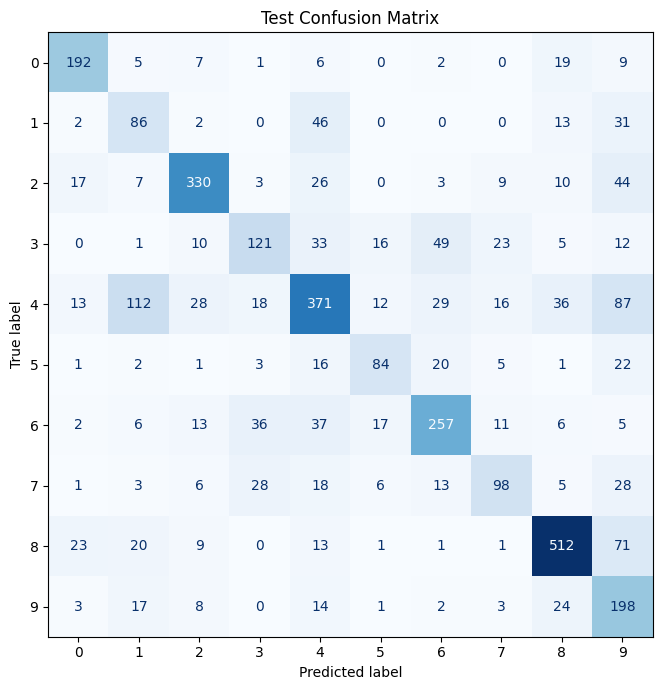

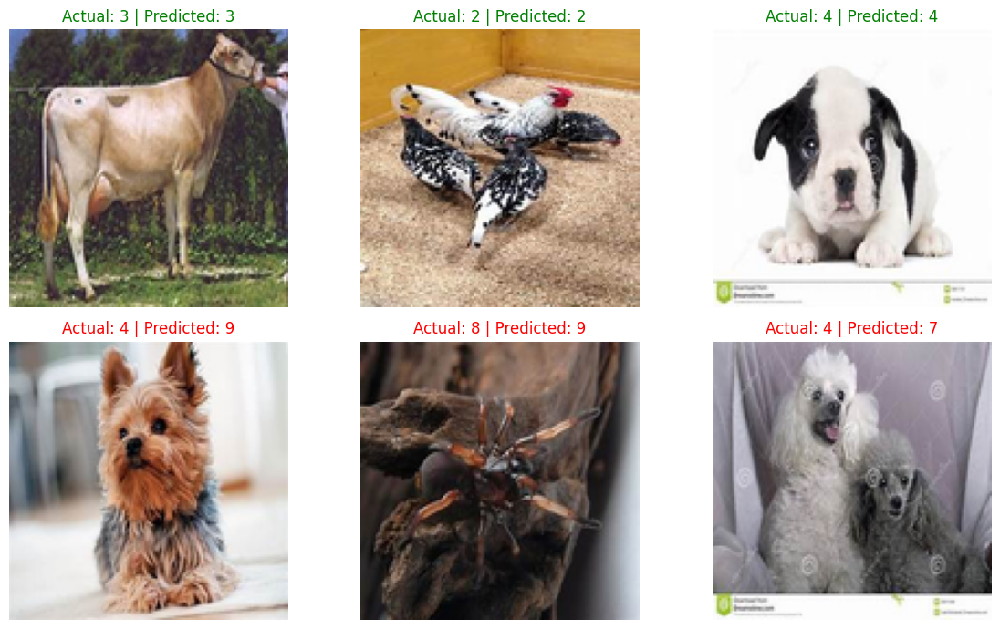

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

# توقعات الموديل لكل صور الـTest بالترتيب
probabilities = best_model.predict(test_dataset, verbose=1)
predicted_labels = probabilities.argmax(axis=1)
true_labels = np.asarray(y_test).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

# Precision وRecall وF1 لكل فئة
print(classification_report(
    true_labels,
    predicted_labels,
    labels=class_ids,
    digits=3,
    zero_division=0,
))

# الصف هو الفئة الحقيقية والعمود هو الفئة اللي توقعها الموديل
matrix = confusion_matrix(true_labels, predicted_labels, labels=class_ids)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(matrix, display_labels=class_ids).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

# اعرض 6 صور عشوائية من الـTest مع النتيجة الفعلية والمتوقعة
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=6, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, index in zip(axes.flat, indices):
    image = X_test[index].astype(np.float32) / PIXEL_SCALE
    actual = true_labels[index]
    predicted = predicted_labels[index]

    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(
        f"Actual: {actual} | Predicted: {predicted}",
        color="green" if actual == predicted else "red",
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path
import tensorflow as tf

current_path = Path("/kaggle/working/models/animals10_baseline_cnn.keras")
improved_path = Path("/kaggle/working/models/animals10_extended_cnn.keras")

continued_model = tf.keras.models.load_model(str(current_path))
current_metrics = continued_model.evaluate(
    val_dataset, return_dict=True, verbose=0
)
current_val_accuracy = float(current_metrics["accuracy"])
print(f"Current validation accuracy: {current_val_accuracy:.2%}")

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(improved_path),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=current_val_accuracy,
    verbose=1,
)

history_extended = continued_model.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=10,
    epochs=20,
    callbacks=[checkpoint],
)

new_best = max(history_extended.history["val_accuracy"])
print(f"Best validation accuracy in epochs 11–20: {new_best:.2%}")

if new_best > current_val_accuracy:
    print(f"Improved model saved to: {improved_path}")
else:
    print("Validation accuracy did not improve. Keep the original model.")

Current validation accuracy: 64.48%
Epoch 11/20
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6604 - loss: 0.9643
Epoch 11: val_accuracy did not improve from 0.64478
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 26s 23ms/step - accuracy: 0.6676 - loss: 0.9539 - val_accuracy: 0.5938 - val_loss: 1.1102
Epoch 12/20
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6747 - loss: 0.9219
Epoch 12: val_accuracy improved from 0.64478 to 0.65016, saving model to /kaggle/working/models/animals10_extended_cnn.keras

Epoch 12: finished saving model to /kaggle/working/models/animals10_extended_cnn.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.6807 - loss: 0.9151 - val_accuracy: 0.6502 - val_loss: 0.9834
Epoch 13/20
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6975 - loss: 0.8681
Epoch 13: val_accuracy improved from 0.65016 to 0.65468, saving model to /kaggle/working/models/animals10_extended_cnn.keras

Epoch 13: finished saving model to /kaggle/working/models/ani

In [24]:
extended_model = tf.keras.models.load_model(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)

test_loss, test_accuracy = extended_model.evaluate(test_dataset, verbose=1)

difference = (test_accuracy - 0.6412) * 100
print(f"New test accuracy: {test_accuracy:.2%}")
print(f"New test loss: {test_loss:.4f}")
print(f"Change vs. original test accuracy: {difference:+.2f} percentage points")

111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7026 - loss: 0.8857
New test accuracy: 70.26%
New test loss: 0.8857
Change vs. original test accuracy: +6.14 percentage points


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_PATH = "/kaggle/input/your-dataset/animal.jpg"

with Image.open(IMAGE_PATH) as image_file:
    original_image = image_file.convert("RGB")

height, width = INPUT_SHAPE[:2]
resized_image = original_image.resize((width, height), Image.Resampling.BILINEAR)

# صور JPG بتكون قيمها من 0 لـ255، والموديل اتدرّب على قيم من 0 لـ1
image_array = np.asarray(resized_image, dtype=np.float32) / 255.0
batch = np.expand_dims(image_array, axis=0)

scores = extended_model.predict(batch, verbose=0)[0]
top_ids = np.argsort(scores)[-3:][::-1]
predicted_id = int(top_ids[0])

plt.imshow(original_image)
plt.title(f"Predicted class: {predicted_id} ({scores[predicted_id]:.1%})")
plt.axis("off")
plt.show()

print("Top 3 predictions:")
for class_id in top_ids:
    print(f"Class {class_id}: {scores[class_id]:.1%}")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/your-dataset/animal.jpg'

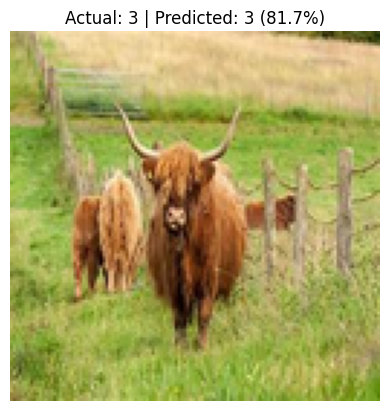

In [26]:
import numpy as np
import matplotlib.pyplot as plt

index = 0
image = X_test[index].astype(np.float32) / PIXEL_SCALE

scores = extended_model.predict(image[None, ...], verbose=0)[0]
predicted = int(np.argmax(scores))
actual = int(y_test[index])

plt.imshow(np.clip(image, 0, 1))
plt.title(f"Actual: {actual} | Predicted: {predicted} ({scores[predicted]:.1%})")
plt.axis("off")
plt.show()

In [27]:
import tensorflow as tf

current_path = "/kaggle/working/models/animals10_extended_cnn.keras"
augmented_path = "/kaggle/working/models/animals10_augmented_cnn.keras"

model_aug = tf.keras.models.load_model(current_path)

previous_val_accuracy = float(
    model_aug.evaluate(val_dataset, return_dict=True, verbose=0)["accuracy"]
)
print(f"Validation accuracy before augmentation: {previous_val_accuracy:.2%}")

# قلّل سرعة التعلّم وإنت بتكمّل على الأوزان الحالية
model_aug.optimizer.learning_rate.assign(0.0003)

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

def augment_batch(images, labels):
    return augmentation(images, training=True), labels

# الـAugmentation على الـTrain بس
augmented_train = train_dataset.map(augment_batch).prefetch(1)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=augmented_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=previous_val_accuracy,
    verbose=1,
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    baseline=previous_val_accuracy,
    patience=4,
)

history_aug = model_aug.fit(
    augmented_train,
    validation_data=val_dataset,
    epochs=12,
    callbacks=[checkpoint, early_stop],
)

best_val_accuracy = max(history_aug.history["val_accuracy"])
print(f"Best validation accuracy: {best_val_accuracy:.2%}")

if best_val_accuracy > previous_val_accuracy:
    selected_model = tf.keras.models.load_model(augmented_path)
    test_result = selected_model.evaluate(test_dataset, return_dict=True)
    print(f"New test accuracy: {test_result['accuracy']:.2%}")
    print(f"New test loss: {test_result['loss']:.4f}")
else:
    print("Validation accuracy did not improve. Keep the extended model.")

Validation accuracy before augmentation: 70.42%
Epoch 1/12
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7565 - loss: 0.7002
Epoch 1: val_accuracy did not improve from 0.70422
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 83s 77ms/step - accuracy: 0.7636 - loss: 0.6821 - val_accuracy: 0.6533 - val_loss: 1.0539
Epoch 2/12
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7719 - loss: 0.6546
Epoch 2: val_accuracy did not improve from 0.70422
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 78s 74ms/step - accuracy: 0.7720 - loss: 0.6568 - val_accuracy: 0.6456 - val_loss: 1.0981
Epoch 3/12
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7776 - loss: 0.6390
Epoch 3: val_accuracy did not improve from 0.70422
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 78s 74ms/step - accuracy: 0.7756 - loss: 0.6429 - val_accuracy: 0.6485 - val_loss: 1.0778
Epoch 4/12
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7795 - loss: 0.6345
Epoch 4: val_accuracy did not improve from 0.70422
1053/1053 ━━━━━━━━━━━━━━━━━━━

In [28]:
from pathlib import Path
from IPython.display import FileLink, display
import os

model_path = Path("/kaggle/working/models/animals10_extended_cnn.keras")

if not model_path.is_file():
    raise FileNotFoundError(f"Model file not found: {model_path}")

display(FileLink(os.path.relpath(model_path)))

/kaggle/working/models/animals10_extended_cnn.keras

In [69]:
import io

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display
from PIL import Image

model = tf.keras.models.load_model(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)

# ضيف أسماء الحيوانات هنا باستخدام ترتيب الـlabels الحقيقي من فريق الداتا.
# مثال فقط: CLASS_NAMES = {0: "اسم الحيوان صاحب الـID 0"}
CLASS_NAMES = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload image",
)
output = widgets.Output()

def predict_uploaded_image(change):
    files = change["new"]
    if not files:
        return

    # دعم شكل الملف في الإصدارات المختلفة من ipywidgets
    uploaded_file = next(iter(files.values())) if isinstance(files, dict) else files[0]

    with output:
        output.clear_output(wait=True)

        with Image.open(io.BytesIO(bytes(uploaded_file["content"]))) as image_file:
            image = image_file.convert("RGB")

        height, width = model.input_shape[1:3]
        resized = image.resize((width, height), Image.Resampling.BILINEAR)
        pixels = np.asarray(resized, dtype=np.float32) / 255.0

        scores = model.predict(pixels[None, ...], verbose=0)[0]
        top_ids = np.argsort(scores)[-3:][::-1]

        plt.imshow(image)
        plt.axis("off")
        plt.show()

        print("Top 3 predictions")
        for class_id in top_ids:
            name = CLASS_NAMES.get(int(class_id), f"Class {class_id}")
            print(f"{name}: {scores[class_id]:.1%}")

upload.observe(predict_uploaded_image, names="value")
display(upload, output)

FileUpload(value=(), accept='image/*', description='Upload image')

Output()

In [31]:
from pathlib import Path
import tensorflow as tf

model_path = Path("/kaggle/working/models/animals10_extended_cnn.keras")

if not model_path.is_file():
    print(f"Checkpoint not found: {model_path}")
else:
    evaluation_model = tf.keras.models.load_model(model_path)
    val_results = evaluation_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Validation results:")
    for metric_name, metric_value in val_results.items():
        print(f"{metric_name}: {metric_value:.4f}")

Validation results:
accuracy: 0.7042
loss: 0.8780


In [32]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

val_probabilities = evaluation_model.predict(val_dataset, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Validation classification report:")
print(
    classification_report(
        val_true_labels,
        val_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

print("Validation confusion matrix:")
print(confusion_matrix(val_true_labels, val_predictions, labels=class_ids))

Validation classification report:
              precision    recall  f1-score   support

           0      0.789     0.812     0.801       240
           1      0.452     0.600     0.516       180
           2      0.853     0.842     0.848       449
           3      0.516     0.717     0.600       269
           4      0.810     0.538     0.647       721
           5      0.706     0.571     0.631       156
           6      0.589     0.710     0.644       390
           7      0.498     0.676     0.574       207
           8      0.830     0.854     0.842       651
           9      0.804     0.607     0.692       270

    accuracy                          0.704      3533
   macro avg      0.685     0.693     0.679      3533
weighted avg      0.729     0.704     0.707      3533

Validation confusion matrix:
[[195   1   7   4   3   0   4   2  22   2]
 [  5 108   1   5  29   3   6   3  12   8]
 [  4   4 378   4  11   2  17  19   5   5]
 [  1   0   2 193   8   4  30  31   0   0]
 [  6 

In [33]:
from pathlib import Path
import tensorflow as tf

base_model_path = Path("/kaggle/working/models/animals10_extended_cnn.keras")
trial_model_path = Path("/kaggle/working/models/animals10_trial_lr_0_0003.keras")

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

trial_model = tf.keras.models.load_model(base_model_path)
trial_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(trial_model_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

trial_history = trial_model.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if trial_model_path.is_file():
    best_trial_model = tf.keras.models.load_model(trial_model_path)
    trial_val_results = best_trial_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Trial validation results:")
    for metric_name, metric_value in trial_val_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No trial checkpoint was saved.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8297 - loss: 0.5096
Epoch 21: val_loss improved from None to 0.81891, saving model to /kaggle/working/models/animals10_trial_lr_0_0003.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - accuracy: 0.8344 - loss: 0.4958 - val_accuracy: 0.7294 - val_loss: 0.8189
Epoch 22/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8430 - loss: 0.4695
Epoch 22: val_loss improved from 0.81891 to 0.81696, saving model to /kaggle/working/models/animals10_trial_lr_0_0003.keras

Epoch 22: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 24s 23ms/step - accuracy: 0.8400 - loss: 0.4776 - val_accuracy: 0.7314 - val_loss: 0.8170
Epoch 23/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8445 - loss: 0.4636
Epoch 23: val_loss improved from 0.81696 to 0.79915, saving m

In [34]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

trial_val_probabilities = best_trial_model.predict(val_dataset, verbose=0)
trial_val_predictions = trial_val_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Trial validation classification report:")
print(
    classification_report(
        val_true_labels,
        trial_val_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

print("Trial validation confusion matrix:")
print(
    confusion_matrix(
        val_true_labels,
        trial_val_predictions,
        labels=class_ids,
    )
)

Trial validation classification report:
              precision    recall  f1-score   support

           0      0.804     0.821     0.812       240
           1      0.496     0.678     0.573       180
           2      0.847     0.889     0.867       449
           3      0.609     0.665     0.636       269
           4      0.779     0.660     0.715       721
           5      0.783     0.577     0.664       156
           6      0.688     0.713     0.700       390
           7      0.588     0.691     0.636       207
           8      0.862     0.862     0.862       651
           9      0.755     0.707     0.730       270

    accuracy                          0.746      3533
   macro avg      0.721     0.726     0.720      3533
weighted avg      0.754     0.746     0.747      3533

Trial validation confusion matrix:
[[197   1   8   1   2   1   3   1  22   4]
 [  3 122   1   1  27   3   1   2   8  12]
 [  4   5 399   1  16   1   6   7   2   8]
 [  0   1   9 179  21   5  26  28   0

In [35]:
from pathlib import Path
import tensorflow as tf

source_model_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)
lower_lr_model_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0001.keras"
)

if not source_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {source_model_path}")

lower_lr_model = tf.keras.models.load_model(source_model_path)
lower_lr_model.optimizer.learning_rate.assign(0.0001)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(lower_lr_model_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

lower_lr_history = lower_lr_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=8,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if lower_lr_model_path.is_file():
    best_lower_lr_model = tf.keras.models.load_model(lower_lr_model_path)
    lower_lr_val_results = best_lower_lr_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Lower learning rate validation results:")
    for metric_name, metric_value in lower_lr_val_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No lower learning rate checkpoint was saved.")

Epoch 1/8
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8592 - loss: 0.4353
Epoch 1: val_loss improved from None to 0.79692, saving model to /kaggle/working/models/animals10_trial_lr_0_0001.keras

Epoch 1: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0001.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - accuracy: 0.8610 - loss: 0.4253 - val_accuracy: 0.7416 - val_loss: 0.7969
Epoch 2/8
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8646 - loss: 0.4130
Epoch 2: val_loss did not improve from 0.79692
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 24s 22ms/step - accuracy: 0.8621 - loss: 0.4199 - val_accuracy: 0.7382 - val_loss: 0.8006
Epoch 3/8
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8614 - loss: 0.4182
Epoch 3: val_loss did not improve from 0.79692
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8629 - loss: 0.4150 - val_accuracy: 0.7359 - val_loss: 0.8151
Epoch 4/8
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8

In [36]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

lower_lr_probabilities = best_lower_lr_model.predict(val_dataset, verbose=0)
lower_lr_predictions = lower_lr_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Lower learning rate validation classification report:")
print(
    classification_report(
        val_true_labels,
        lower_lr_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

print("Lower learning rate validation confusion matrix:")
print(
    confusion_matrix(
        val_true_labels,
        lower_lr_predictions,
        labels=class_ids,
    )
)

Lower learning rate validation classification report:
              precision    recall  f1-score   support

           0      0.798     0.838     0.817       240
           1      0.481     0.644     0.551       180
           2      0.876     0.884     0.880       449
           3      0.603     0.706     0.651       269
           4      0.798     0.607     0.690       721
           5      0.653     0.712     0.681       156
           6      0.718     0.679     0.698       390
           7      0.582     0.686     0.630       207
           8      0.862     0.856     0.859       651
           9      0.690     0.752     0.720       270

    accuracy                          0.742      3533
   macro avg      0.706     0.736     0.718      3533
weighted avg      0.753     0.742     0.743      3533

Lower learning rate validation confusion matrix:
[[201   2   5   1   1   0   4   2  18   6]
 [  3 116   1   2  25   3   1   2   9  18]
 [  3   5 397   3  15   2   5   8   1  10]
 [  0   1

In [37]:
from pathlib import Path
import tensorflow as tf

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
fair_trial_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0001_from_base.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

fair_trial_model = tf.keras.models.load_model(base_model_path)
fair_trial_model.optimizer.learning_rate.assign(0.0001)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(fair_trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

fair_trial_history = fair_trial_model.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if fair_trial_path.is_file():
    best_fair_trial_model = tf.keras.models.load_model(fair_trial_path)
    fair_trial_results = best_fair_trial_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Fair lower learning rate validation results:")
    for metric_name, metric_value in fair_trial_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No fair trial checkpoint was saved.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8344 - loss: 0.5000
Epoch 21: val_loss improved from None to 0.79831, saving model to /kaggle/working/models/animals10_trial_lr_0_0001_from_base.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0001_from_base.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.8393 - loss: 0.4840 - val_accuracy: 0.7373 - val_loss: 0.7983
Epoch 22/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8473 - loss: 0.4667
Epoch 22: val_loss improved from 0.79831 to 0.79402, saving model to /kaggle/working/models/animals10_trial_lr_0_0001_from_base.keras

Epoch 22: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0001_from_base.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8450 - loss: 0.4672 - val_accuracy: 0.7396 - val_loss: 0.7940
Epoch 23/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8478 - loss: 0.4586
Epoch 23: val_loss di

In [38]:
import numpy as np
from sklearn.metrics import classification_report

fair_trial_probabilities = best_fair_trial_model.predict(
    val_dataset,
    verbose=0,
)
fair_trial_predictions = fair_trial_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Fair lower learning rate validation classification report:")
print(
    classification_report(
        val_true_labels,
        fair_trial_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Fair lower learning rate validation classification report:
              precision    recall  f1-score   support

           0      0.784     0.833     0.808       240
           1      0.424     0.694     0.526       180
           2      0.852     0.886     0.869       449
           3      0.638     0.662     0.650       269
           4      0.778     0.617     0.688       721
           5      0.646     0.750     0.694       156
           6      0.716     0.705     0.711       390
           7      0.626     0.623     0.625       207
           8      0.881     0.843     0.862       651
           9      0.727     0.730     0.728       270

    accuracy                          0.740      3533
   macro avg      0.707     0.734     0.716      3533
weighted avg      0.753     0.740     0.742      3533



In [39]:
from pathlib import Path
import tensorflow as tf

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
trial_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0005.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

trial_model_0005 = tf.keras.models.load_model(base_model_path)
trial_model_0005.optimizer.learning_rate.assign(0.0005)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

history_0005 = trial_model_0005.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if trial_path.is_file():
    best_model_0005 = tf.keras.models.load_model(trial_path)
    results_0005 = best_model_0005.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Learning rate 0.0005 validation results:")
    for metric_name, metric_value in results_0005.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No checkpoint was saved for learning rate 0.0005.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8220 - loss: 0.5280
Epoch 21: val_loss improved from None to 0.81732, saving model to /kaggle/working/models/animals10_trial_lr_0_0005.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0005.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.8257 - loss: 0.5190 - val_accuracy: 0.7314 - val_loss: 0.8173
Epoch 22/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8247 - loss: 0.5105
Epoch 22: val_loss did not improve from 0.81732
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8311 - loss: 0.4966 - val_accuracy: 0.7320 - val_loss: 0.8206
Epoch 23/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8393 - loss: 0.4788
Epoch 23: val_loss did not improve from 0.81732
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8367 - loss: 0.4834 - val_accuracy: 0.7223 - val_loss: 0.8456
Epoch 24/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - a

In [40]:
import numpy as np
from sklearn.metrics import classification_report

probabilities_0005 = best_model_0005.predict(val_dataset, verbose=0)
predictions_0005 = probabilities_0005.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Learning rate 0.0005 validation classification report:")
print(
    classification_report(
        val_true_labels,
        predictions_0005,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Learning rate 0.0005 validation classification report:
              precision    recall  f1-score   support

           0      0.804     0.787     0.796       240
           1      0.507     0.628     0.561       180
           2      0.782     0.920     0.845       449
           3      0.555     0.747     0.637       269
           4      0.808     0.589     0.682       721
           5      0.629     0.718     0.671       156
           6      0.677     0.682     0.679       390
           7      0.688     0.575     0.626       207
           8      0.852     0.868     0.860       651
           9      0.734     0.685     0.709       270

    accuracy                          0.733      3533
   macro avg      0.704     0.720     0.707      3533
weighted avg      0.743     0.733     0.732      3533



In [41]:
from pathlib import Path
import tensorflow as tf

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
trial_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0002.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

trial_model_0002 = tf.keras.models.load_model(base_model_path)
trial_model_0002.optimizer.learning_rate.assign(0.0002)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

history_0002 = trial_model_0002.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if trial_path.is_file():
    best_model_0002 = tf.keras.models.load_model(trial_path)
    results_0002 = best_model_0002.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Learning rate 0.0002 validation results:")
    for metric_name, metric_value in results_0002.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No checkpoint was saved for learning rate 0.0002.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8369 - loss: 0.4879
Epoch 21: val_loss improved from None to 0.80451, saving model to /kaggle/working/models/animals10_trial_lr_0_0002.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0002.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - accuracy: 0.8375 - loss: 0.4879 - val_accuracy: 0.7308 - val_loss: 0.8045
Epoch 22/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8415 - loss: 0.4741
Epoch 22: val_loss did not improve from 0.80451
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8427 - loss: 0.4710 - val_accuracy: 0.7356 - val_loss: 0.8059
Epoch 23/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8432 - loss: 0.4635
Epoch 23: val_loss improved from 0.80451 to 0.80451, saving model to /kaggle/working/models/animals10_trial_lr_0_0002.keras

Epoch 23: finished saving model to /kaggle/working/models/animals10_trial_lr_0_0002.keras
1053/1053 ━━━

In [42]:
import numpy as np
from sklearn.metrics import classification_report

probabilities_0002 = best_model_0002.predict(val_dataset, verbose=0)
predictions_0002 = probabilities_0002.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Learning rate 0.0002 validation classification report:")
print(
    classification_report(
        val_true_labels,
        predictions_0002,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Learning rate 0.0002 validation classification report:
              precision    recall  f1-score   support

           0      0.810     0.800     0.805       240
           1      0.451     0.639     0.529       180
           2      0.822     0.893     0.856       449
           3      0.590     0.680     0.632       269
           4      0.756     0.650     0.699       721
           5      0.667     0.654     0.660       156
           6      0.752     0.636     0.689       390
           7      0.606     0.662     0.633       207
           8      0.855     0.859     0.857       651
           9      0.742     0.715     0.728       270

    accuracy                          0.736      3533
   macro avg      0.705     0.719     0.709      3533
weighted avg      0.744     0.736     0.737      3533



In [43]:
import numpy as np
import tensorflow as tf
from pathlib import Path

def make_dataset_with_batch_size(images, labels, batch_size, training=False):
    sample_indices = train_indices if training else np.arange(len(images))

    def batches():
        indices = sample_indices
        if training:
            indices = np.random.default_rng().permutation(sample_indices)

        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]
            pixels = images[batch_indices].astype(np.float32) / PIXEL_SCALE
            yield pixels, labels[batch_indices]

    signature = (
        tf.TensorSpec((None, *INPUT_SHAPE), tf.float32),
        tf.TensorSpec((None,), tf.int32),
    )
    dataset = tf.data.Dataset.from_generator(
        batches,
        output_signature=signature,
    )

    batch_count = (len(sample_indices) + batch_size - 1) // batch_size
    return dataset.apply(
        tf.data.experimental.assert_cardinality(batch_count)
    ).prefetch(1)


train_dataset_64 = make_dataset_with_batch_size(
    X_train, y_train, batch_size=64, training=True
)
val_dataset_64 = make_dataset_with_batch_size(
    X_val, y_val, batch_size=64
)

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
trial_path = Path(
    "/kaggle/working/models/animals10_trial_batch_64.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

batch_trial_model = tf.keras.models.load_model(base_model_path)
batch_trial_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

batch_trial_history = batch_trial_model.fit(
    train_dataset_64,
    validation_data=val_dataset_64,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if trial_path.is_file():
    best_batch_trial_model = tf.keras.models.load_model(trial_path)
    batch_trial_results = best_batch_trial_model.evaluate(
        val_dataset_64,
        return_dict=True,
        verbose=0,
    )

    print("Batch size 64 validation results:")
    for metric_name, metric_value in batch_trial_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No checkpoint was saved for batch size 64.")

Epoch 21/30


E0000 00:00:1795786443.236297     164 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


527/527 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8373 - loss: 0.4946
Epoch 21: val_loss improved from None to 0.81872, saving model to /kaggle/working/models/animals10_trial_batch_64.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_batch_64.keras
527/527 ━━━━━━━━━━━━━━━━━━━━ 31s 46ms/step - accuracy: 0.8388 - loss: 0.4855 - val_accuracy: 0.7206 - val_loss: 0.8187
Epoch 22/30
527/527 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8445 - loss: 0.4662
Epoch 22: val_loss improved from 0.81872 to 0.80137, saving model to /kaggle/working/models/animals10_trial_batch_64.keras

Epoch 22: finished saving model to /kaggle/working/models/animals10_trial_batch_64.keras
527/527 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.8416 - loss: 0.4713 - val_accuracy: 0.7371 - val_loss: 0.8014
Epoch 23/30
527/527 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8457 - loss: 0.4624
Epoch 23: val_loss did not improve from 0.80137
527/527 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/s

In [44]:
import numpy as np
from sklearn.metrics import classification_report

batch_64_probabilities = best_batch_trial_model.predict(
    val_dataset_64,
    verbose=0,
)
batch_64_predictions = batch_64_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Batch size 64 validation classification report:")
print(
    classification_report(
        val_true_labels,
        batch_64_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Batch size 64 validation classification report:
              precision    recall  f1-score   support

           0      0.776     0.821     0.798       240
           1      0.436     0.683     0.532       180
           2      0.897     0.853     0.874       449
           3      0.611     0.673     0.641       269
           4      0.763     0.642     0.697       721
           5      0.760     0.628     0.688       156
           6      0.698     0.692     0.695       390
           7      0.601     0.662     0.630       207
           8      0.844     0.863     0.853       651
           9      0.739     0.704     0.721       270

    accuracy                          0.737      3533
   macro avg      0.712     0.722     0.713      3533
weighted avg      0.749     0.737     0.740      3533



In [45]:
from pathlib import Path
import tensorflow as tf

train_dataset_16 = make_dataset_with_batch_size(
    X_train, y_train, batch_size=16, training=True
)
val_dataset_16 = make_dataset_with_batch_size(
    X_val, y_val, batch_size=16
)

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
trial_path = Path(
    "/kaggle/working/models/animals10_trial_batch_16.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

batch_trial_model_16 = tf.keras.models.load_model(base_model_path)
batch_trial_model_16.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

history_batch_16 = batch_trial_model_16.fit(
    train_dataset_16,
    validation_data=val_dataset_16,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if trial_path.is_file():
    best_batch_16_model = tf.keras.models.load_model(trial_path)
    results_batch_16 = best_batch_16_model.evaluate(
        val_dataset_16,
        return_dict=True,
        verbose=0,
    )

    print("Batch size 16 validation results:")
    for metric_name, metric_value in results_batch_16.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No checkpoint was saved for batch size 16.")

Epoch 21/30
2105/2105 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8231 - loss: 0.5336
Epoch 21: val_loss improved from None to 0.86465, saving model to /kaggle/working/models/animals10_trial_batch_16.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_batch_16.keras
2105/2105 ━━━━━━━━━━━━━━━━━━━━ 29s 13ms/step - accuracy: 0.8246 - loss: 0.5193 - val_accuracy: 0.7042 - val_loss: 0.8647
Epoch 22/30
2101/2105 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8319 - loss: 0.4898
Epoch 22: val_loss improved from 0.86465 to 0.85822, saving model to /kaggle/working/models/animals10_trial_batch_16.keras

Epoch 22: finished saving model to /kaggle/working/models/animals10_trial_batch_16.keras
2105/2105 ━━━━━━━━━━━━━━━━━━━━ 25s 12ms/step - accuracy: 0.8335 - loss: 0.4923 - val_accuracy: 0.7130 - val_loss: 0.8582
Epoch 23/30
2105/2105 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8413 - loss: 0.4706
Epoch 23: val_loss improved from 0.85822 to 0.79671, saving model

In [46]:
import numpy as np
from sklearn.metrics import classification_report

batch_16_probabilities = best_batch_16_model.predict(
    val_dataset_16,
    verbose=0,
)
batch_16_predictions = batch_16_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Batch size 16 validation classification report:")
print(
    classification_report(
        val_true_labels,
        batch_16_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Batch size 16 validation classification report:
              precision    recall  f1-score   support

           0      0.825     0.767     0.795       240
           1      0.502     0.633     0.560       180
           2      0.842     0.875     0.858       449
           3      0.683     0.617     0.648       269
           4      0.814     0.584     0.680       721
           5      0.681     0.712     0.696       156
           6      0.652     0.754     0.699       390
           7      0.582     0.734     0.650       207
           8      0.855     0.877     0.866       651
           9      0.668     0.774     0.717       270

    accuracy                          0.740      3533
   macro avg      0.710     0.733     0.717      3533
weighted avg      0.751     0.740     0.740      3533



In [47]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

final_model_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)

if not final_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {final_model_path}")

final_model = tf.keras.models.load_model(final_model_path)

test_results = final_model.evaluate(
    test_dataset,
    return_dict=True,
    verbose=0,
)

print("Final test results:")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

test_probabilities = final_model.predict(test_dataset, verbose=0)
test_predictions = test_probabilities.argmax(axis=1)
test_true_labels = np.asarray(y_test).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Test classification report:")
print(
    classification_report(
        test_true_labels,
        test_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

print("Test confusion matrix:")
print(confusion_matrix(test_true_labels, test_predictions, labels=class_ids))

Final test results:
accuracy: 0.7476
loss: 0.8097
Test classification report:
              precision    recall  f1-score   support

           0      0.812     0.859     0.835       241
           1      0.465     0.622     0.532       180
           2      0.805     0.846     0.825       449
           3      0.607     0.630     0.618       270
           4      0.761     0.636     0.693       722
           5      0.831     0.665     0.738       155
           6      0.709     0.782     0.744       390
           7      0.672     0.665     0.668       206
           8      0.871     0.892     0.882       651
           9      0.729     0.696     0.712       270

    accuracy                          0.748      3534
   macro avg      0.726     0.729     0.725      3534
weighted avg      0.753     0.748     0.748      3534

Test confusion matrix:
[[207   2  10   0   3   0   3   0  15   1]
 [  1 112   2   1  41   0   0   2  10  11]
 [  8  10 380   4  15   1   9   7   6   9]
 [  0   3  

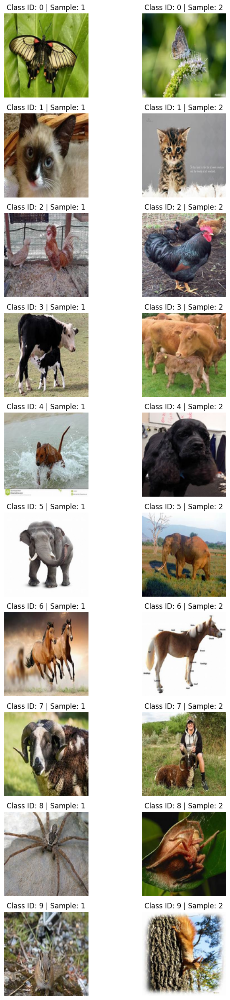

In [48]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
val_labels = np.asarray(y_val).reshape(-1)

fig, axes = plt.subplots(NUM_CLASSES, 2, figsize=(8, 24))

for class_id in range(NUM_CLASSES):
    class_indices = np.flatnonzero(val_labels == class_id)
    selected_indices = rng.choice(
        class_indices,
        size=min(2, len(class_indices)),
        replace=False,
    )

    for column, image_index in enumerate(selected_indices):
        image = X_val[image_index].astype(np.float32) / PIXEL_SCALE

        axes[class_id, column].imshow(np.clip(image, 0, 1))
        axes[class_id, column].set_title(
            f"Class ID: {class_id} | Sample: {column + 1}"
        )
        axes[class_id, column].axis("off")

plt.tight_layout()
plt.show()

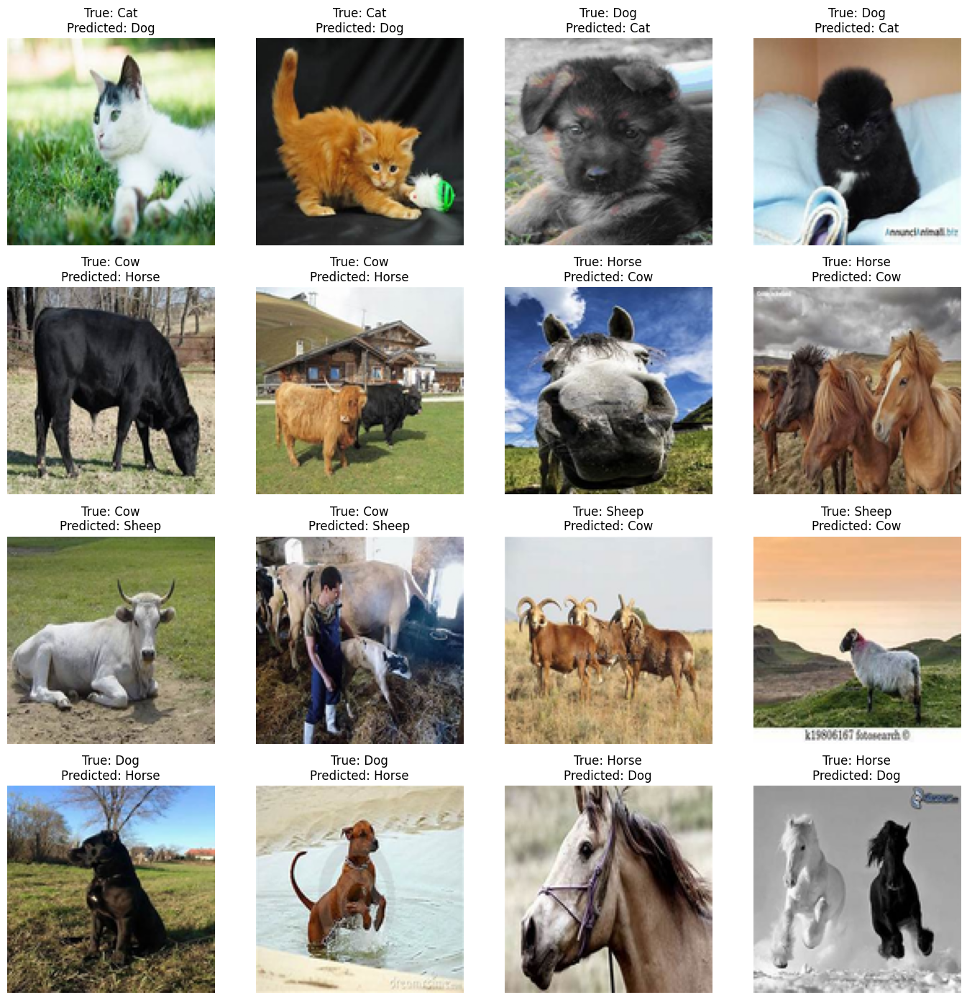

In [49]:
import numpy as np
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

val_true_labels = np.asarray(y_val).reshape(-1)
val_probabilities = best_trial_model.predict(val_dataset, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)

pairs_to_review = [
    (1, 4),  # Cat and Dog
    (3, 6),  # Cow and Horse
    (3, 7),  # Cow and Sheep
    (4, 6),  # Dog and Horse
]

rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(pairs_to_review), 4, figsize=(14, 14))

for row, (class_a, class_b) in enumerate(pairs_to_review):
    directions = [
        (class_a, class_b),
        (class_b, class_a),
    ]
    column = 0

    for true_id, predicted_id in directions:
        mistake_indices = np.flatnonzero(
            (val_true_labels == true_id)
            & (val_predictions == predicted_id)
        )

        selected_indices = rng.choice(
            mistake_indices,
            size=min(2, len(mistake_indices)),
            replace=False,
        )

        for image_index in selected_indices:
            image = X_val[image_index].astype(np.float32) / PIXEL_SCALE
            axes[row, column].imshow(np.clip(image, 0, 1))
            axes[row, column].set_title(
                f"True: {class_names[true_id]}\n"
                f"Predicted: {class_names[predicted_id]}"
            )
            axes[row, column].axis("off")
            column += 1

    while column < 4:
        axes[row, column].axis("off")
        column += 1

plt.tight_layout()
plt.show()

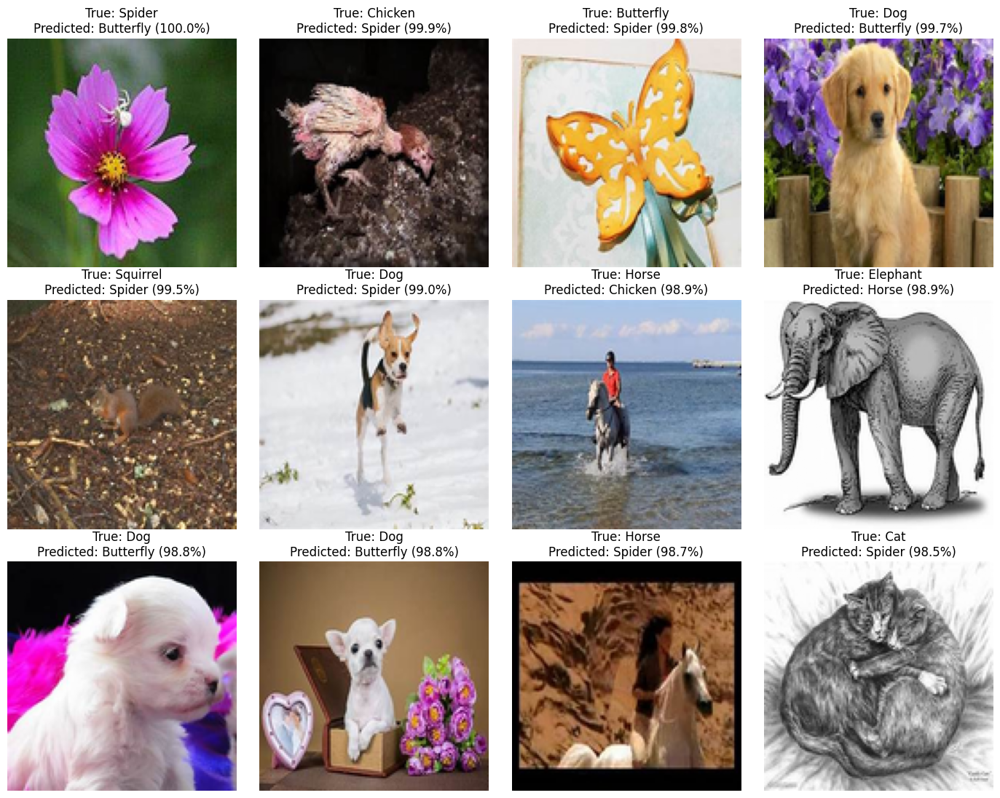

In [50]:
import numpy as np
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

val_true_labels = np.asarray(y_val).reshape(-1)
val_probabilities = best_trial_model.predict(val_dataset, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)
predicted_confidence = val_probabilities.max(axis=1)

error_indices = np.flatnonzero(val_predictions != val_true_labels)
sorted_errors = error_indices[
    np.argsort(predicted_confidence[error_indices])[::-1]
]
selected_errors = sorted_errors[:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for ax, image_index in zip(axes.flat, selected_errors):
    image = X_val[image_index].astype(np.float32) / PIXEL_SCALE
    true_id = int(val_true_labels[image_index])
    predicted_id = int(val_predictions[image_index])
    confidence = float(predicted_confidence[image_index])

    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(
        f"True: {class_names[true_id]}\n"
        f"Predicted: {class_names[predicted_id]} "
        f"({confidence:.1%})"
    )
    ax.axis("off")

for ax in axes.flat[len(selected_errors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

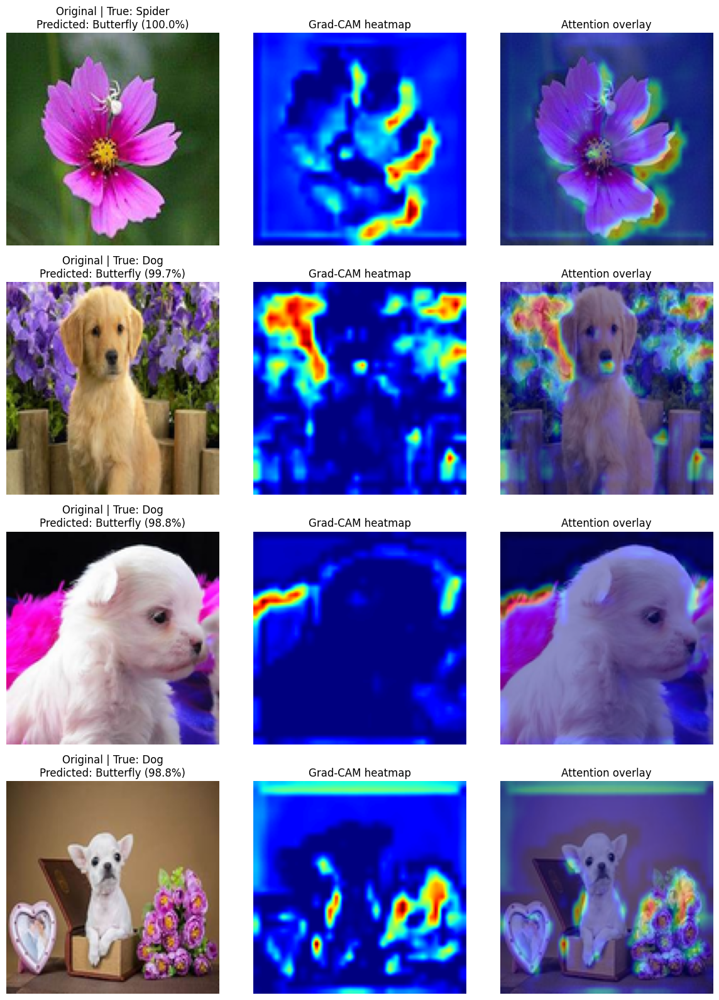

In [51]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

val_true_labels = np.asarray(y_val).reshape(-1)
val_images = X_val

val_probabilities = best_trial_model.predict(val_dataset, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)
val_confidence = val_probabilities.max(axis=1)

butterfly_false_positives = np.flatnonzero(
    (val_true_labels != 0) & (val_predictions == 0)
)
butterfly_false_positives = butterfly_false_positives[
    np.argsort(val_confidence[butterfly_false_positives])[::-1]
][:4]

if len(butterfly_false_positives) == 0:
    print("No validation images were incorrectly predicted as Butterfly.")
else:
    last_conv_layer = next(
        layer
        for layer in reversed(best_trial_model.layers)
        if isinstance(layer, tf.keras.layers.Conv2D)
    )

    grad_cam_model = tf.keras.models.Model(
        inputs=best_trial_model.inputs,
        outputs=[last_conv_layer.output, best_trial_model.output],
    )

    fig, axes = plt.subplots(
        len(butterfly_false_positives),
        3,
        figsize=(12, 4 * len(butterfly_false_positives)),
        squeeze=False,
    )

    for row, image_index in enumerate(butterfly_false_positives):
        image = val_images[image_index].astype(np.float32) / PIXEL_SCALE
        input_tensor = tf.convert_to_tensor(image[None, ...])

        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_cam_model(
                input_tensor,
                training=False,
            )
            predicted_class = int(tf.argmax(predictions[0]).numpy())
            class_score = predictions[:, predicted_class]

        gradients = tape.gradient(class_score, conv_outputs)
        channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
        heatmap = tf.reduce_sum(
            conv_outputs[0] * channel_weights,
            axis=-1,
        )
        heatmap = tf.maximum(heatmap, 0)
        heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

        heatmap = tf.image.resize(
            heatmap[..., tf.newaxis],
            size=image.shape[:2],
        ).numpy().squeeze()

        heatmap_rgb = plt.get_cmap("jet")(heatmap)[..., :3]
        overlay = np.clip(0.55 * image + 0.45 * heatmap_rgb, 0, 1)

        true_class = int(val_true_labels[image_index])
        confidence = float(val_confidence[image_index])

        axes[row, 0].imshow(np.clip(image, 0, 1))
        axes[row, 0].set_title(
            f"Original | True: {class_names[true_class]}\n"
            f"Predicted: Butterfly ({confidence:.1%})"
        )

        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title("Grad-CAM heatmap")

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Attention overlay")

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [52]:
from pathlib import Path
import tensorflow as tf

zoom_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomZoom(
        height_factor=(-0.15, 0.0),
        width_factor=(-0.15, 0.0),
        fill_mode="reflect",
    )
])

def apply_zoom_augmentation(images, labels):
    return zoom_augmentation(images, training=True), labels

zoom_train_dataset = train_dataset.map(
    apply_zoom_augmentation,
    num_parallel_calls=tf.data.AUTOTUNE,
).prefetch(1)

base_model_path = Path(
    "/kaggle/working/models/animals10_extended_cnn.keras"
)
zoom_trial_path = Path(
    "/kaggle/working/models/animals10_trial_zoom_15.keras"
)

if not base_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {base_model_path}")

zoom_trial_model = tf.keras.models.load_model(base_model_path)
zoom_trial_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(zoom_trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

zoom_history = zoom_trial_model.fit(
    zoom_train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if zoom_trial_path.is_file():
    best_zoom_model = tf.keras.models.load_model(zoom_trial_path)
    zoom_results = best_zoom_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Zoom augmentation validation results:")
    for metric_name, metric_value in zoom_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No zoom augmentation checkpoint was saved.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7777 - loss: 0.6433
Epoch 21: val_loss improved from None to 1.13185, saving model to /kaggle/working/models/animals10_trial_zoom_15.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_trial_zoom_15.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 31s 27ms/step - accuracy: 0.7865 - loss: 0.6171 - val_accuracy: 0.6456 - val_loss: 1.1318
Epoch 22/30
1050/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7988 - loss: 0.5867
Epoch 22: val_loss did not improve from 1.13185
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - accuracy: 0.7978 - loss: 0.5868 - val_accuracy: 0.6136 - val_loss: 1.2652
Epoch 23/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7989 - loss: 0.5791
Epoch 23: val_loss did not improve from 1.13185
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - accuracy: 0.8012 - loss: 0.5760 - val_accuracy: 0.6165 - val_loss: 1.2083
Epoch 24/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accur

In [53]:
import numpy as np
from sklearn.metrics import classification_report

zoom_probabilities = best_zoom_model.predict(val_dataset, verbose=0)
zoom_predictions = zoom_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Zoom augmentation validation classification report:")
print(
    classification_report(
        val_true_labels,
        zoom_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Zoom augmentation validation classification report:
              precision    recall  f1-score   support

           0      0.564     0.863     0.682       240
           1      0.569     0.433     0.492       180
           2      0.660     0.893     0.759       449
           3      0.617     0.550     0.582       269
           4      0.798     0.465     0.587       721
           5      0.423     0.705     0.529       156
           6      0.605     0.741     0.666       390
           7      0.604     0.633     0.618       207
           8      0.877     0.748     0.808       651
           9      0.669     0.622     0.645       270

    accuracy                          0.666      3533
   macro avg      0.639     0.665     0.637      3533
weighted avg      0.694     0.666     0.663      3533



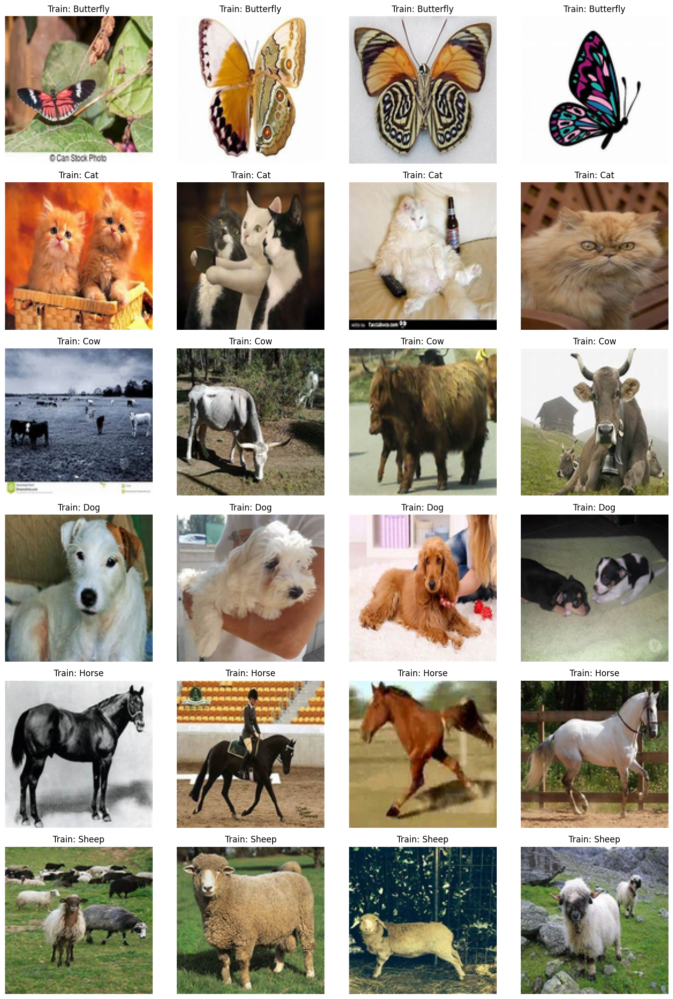

In [54]:
import numpy as np
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    1: "Cat",
    3: "Cow",
    4: "Dog",
    6: "Horse",
    7: "Sheep",
}

train_labels = np.asarray(y_train).reshape(-1)
rng = np.random.default_rng(42)

classes_to_review = list(class_names.keys())
fig, axes = plt.subplots(
    len(classes_to_review),
    4,
    figsize=(14, 20),
)

for row, class_id in enumerate(classes_to_review):
    class_indices = np.flatnonzero(train_labels == class_id)
    selected_indices = rng.choice(
        class_indices,
        size=min(4, len(class_indices)),
        replace=False,
    )

    for column, image_index in enumerate(selected_indices):
        image = X_train[image_index].astype(np.float32) / PIXEL_SCALE
        axes[row, column].imshow(np.clip(image, 0, 1))
        axes[row, column].set_title(
            f"Train: {class_names[class_id]}"
        )
        axes[row, column].axis("off")

    for column in range(len(selected_indices), 4):
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

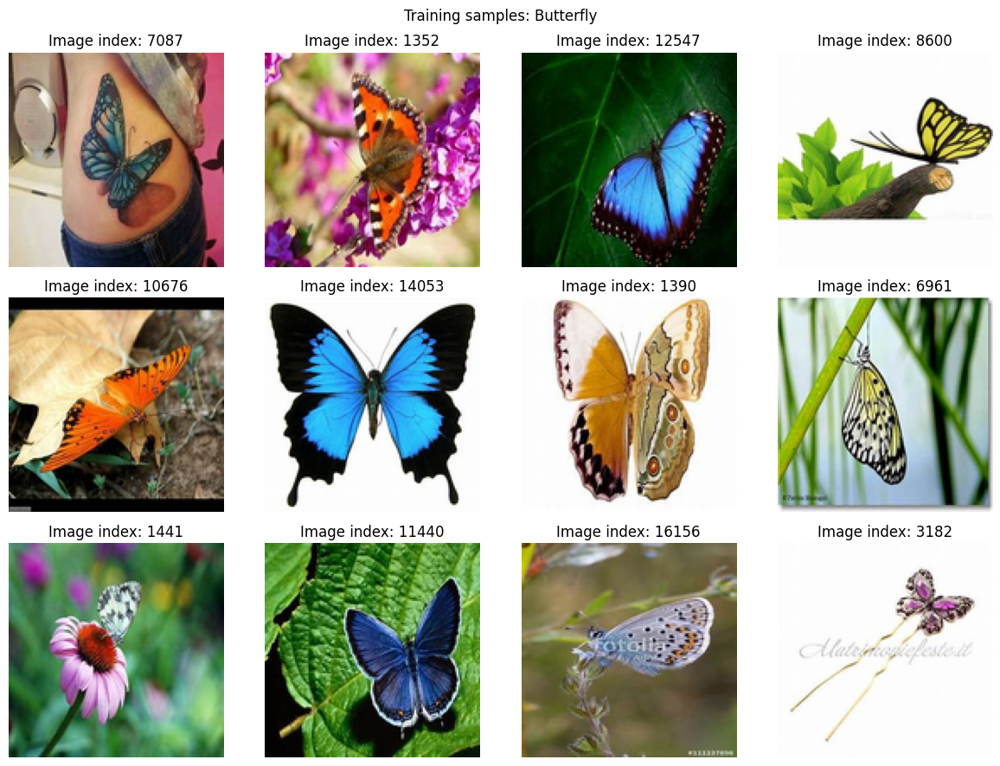

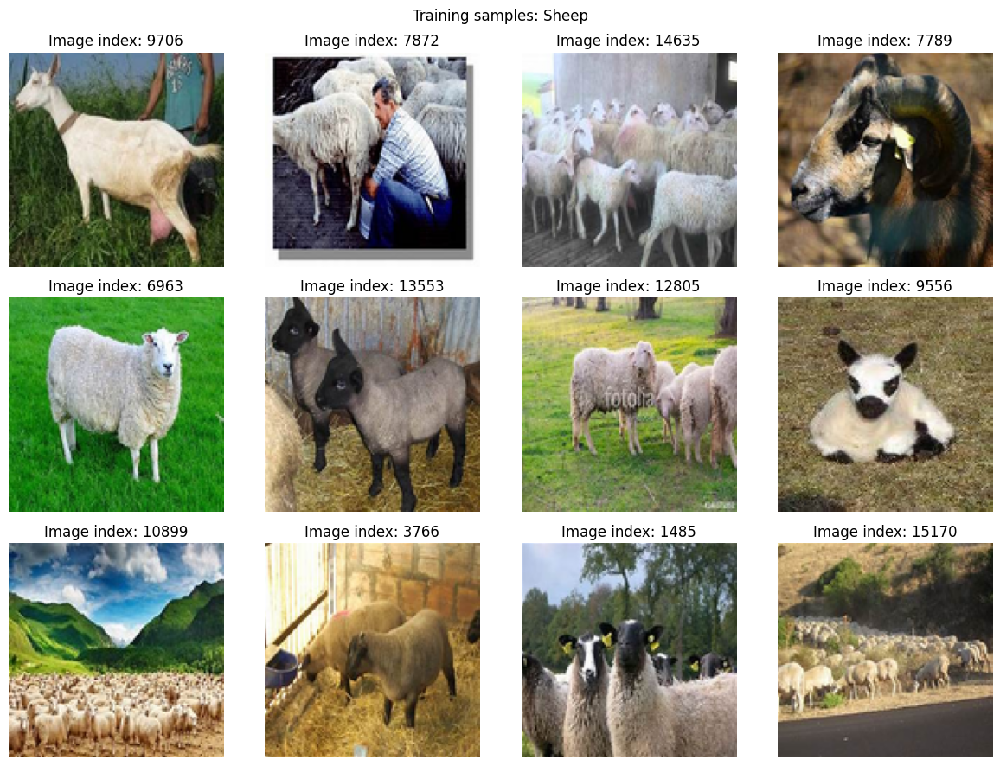

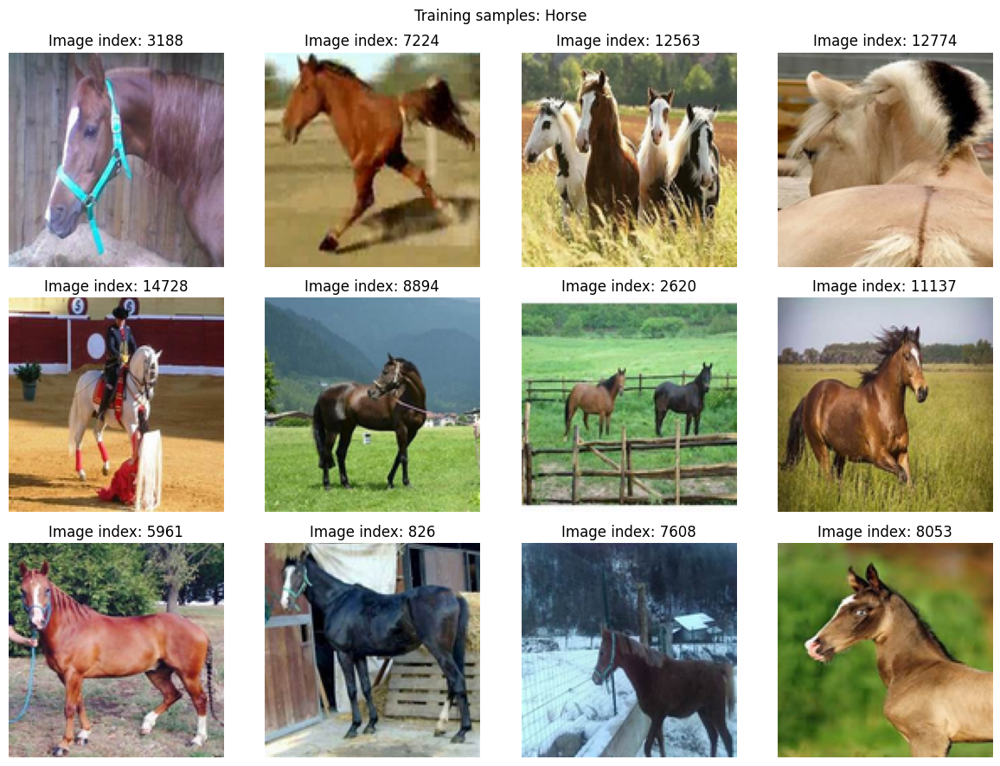

In [55]:
import numpy as np
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    5: "Elephant",
    7: "Sheep",
    6: "Horse",
}

train_labels = np.asarray(y_train).reshape(-1)
rng = np.random.default_rng(42)

for class_id in [0, 7, 6]:
    class_indices = np.flatnonzero(train_labels == class_id)
    selected_indices = rng.choice(
        class_indices,
        size=min(12, len(class_indices)),
        replace=False,
    )

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    fig.suptitle(f"Training samples: {class_names[class_id]}")

    for ax, image_index in zip(axes.flat, selected_indices):
        image = X_train[image_index].astype(np.float32) / PIXEL_SCALE
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(f"Image index: {image_index}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Index 9706: stored label = 7 (Sheep)
Index 9556: stored label = 7 (Sheep)
Index 7224: stored label = 6 (Horse)


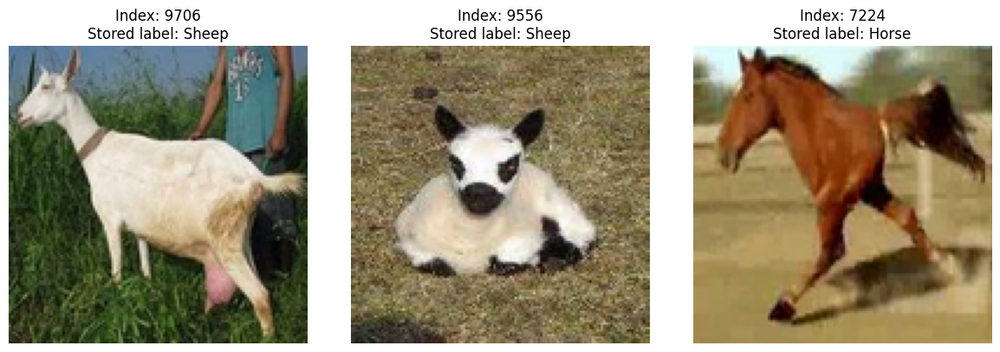

In [56]:
import numpy as np
import matplotlib.pyplot as plt

class_names = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

indices_to_verify = [9706, 9556, 7224]
train_labels = np.asarray(y_train).reshape(-1)

fig, axes = plt.subplots(1, len(indices_to_verify), figsize=(12, 4))

for ax, image_index in zip(axes, indices_to_verify):
    stored_label = int(train_labels[image_index])
    image = X_train[image_index].astype(np.float32) / PIXEL_SCALE

    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(
        f"Index: {image_index}\n"
        f"Stored label: {class_names[stored_label]}"
    )
    ax.axis("off")

    print(
        f"Index {image_index}: "
        f"stored label = {stored_label} ({class_names[stored_label]})"
    )

plt.tight_layout()
plt.show()

In [57]:
import numpy as np

indices_to_check = [9706, 9556, 7224]
train_labels = np.asarray(y_train).reshape(-1)

print("Training occurrences per original image:")
for image_index in indices_to_check:
    stored_label = int(train_labels[image_index])
    occurrence_count = int(np.count_nonzero(train_indices == image_index))

    print(
        f"Index {image_index}: "
        f"class ID {stored_label}, "
        f"occurrences per epoch = {occurrence_count}"
    )

Training occurrences per original image:
Index 9706: class ID 7, occurrences per epoch = 2
Index 9556: class ID 7, occurrences per epoch = 2
Index 7224: class ID 6, occurrences per epoch = 3


In [58]:
import numpy as np

y_train_clean = np.asarray(y_train).copy()

image_index = 9706
original_label = int(y_train_clean[image_index])

if original_label != 7:
    raise ValueError(
        f"Expected Sheep label 7 at index {image_index}, "
        f"but found {original_label}."
    )

y_train_clean[image_index] = 3

print(f"Original label: {original_label} (Sheep)")
print(f"Clean-copy label: {int(y_train_clean[image_index])} (Cow)")
print(f"Original y_train label remains: {int(y_train[image_index])}")

Original label: 7 (Sheep)
Clean-copy label: 3 (Cow)
Original y_train label remains: 7


In [59]:
import numpy as np
import tensorflow as tf
from pathlib import Path

corrected_train_indices = create_balanced_indices(
    y_train_clean,
    random_state=42,
)

def make_dataset_from_indices(
    images,
    labels,
    sample_indices,
    batch_size=32,
    training=False,
):
    sample_indices = np.asarray(sample_indices, dtype=np.int64)

    def batches():
        indices = sample_indices
        if training:
            indices = np.random.default_rng().permutation(sample_indices)

        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]
            pixels = images[batch_indices].astype(np.float32) / PIXEL_SCALE
            yield pixels, labels[batch_indices]

    signature = (
        tf.TensorSpec((None, *INPUT_SHAPE), tf.float32),
        tf.TensorSpec((None,), tf.int32),
    )

    dataset = tf.data.Dataset.from_generator(
        batches,
        output_signature=signature,
    )

    batch_count = (len(sample_indices) + batch_size - 1) // batch_size
    return dataset.apply(
        tf.data.experimental.assert_cardinality(batch_count)
    ).prefetch(1)


clean_train_dataset = make_dataset_from_indices(
    X_train,
    y_train_clean,
    corrected_train_indices,
    batch_size=32,
    training=True,
)

print("Balanced training counts after correction:")
print(
    np.bincount(
        y_train_clean[corrected_train_indices],
        minlength=NUM_CLASSES,
    )
)

source_model_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)
clean_trial_path = Path(
    "/kaggle/working/models/animals10_trial_clean_label_9706.keras"
)

if not source_model_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {source_model_path}")

clean_trial_model = tf.keras.models.load_model(source_model_path)
clean_trial_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clean_trial_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=2,
    restore_best_weights=True,
    verbose=1,
)

clean_trial_history = clean_trial_model.fit(
    clean_train_dataset,
    validation_data=val_dataset,
    epochs=8,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if clean_trial_path.is_file():
    best_clean_trial_model = tf.keras.models.load_model(clean_trial_path)
    clean_trial_results = best_clean_trial_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Corrected label validation results:")
    for metric_name, metric_value in clean_trial_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No corrected-label checkpoint was saved.")

Balanced training counts after correction:
[3368 3368 3368 3368 3368 3368 3368 3368 3368 3368]
Epoch 1/8
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8441 - loss: 0.4647
Epoch 1: val_loss improved from None to 0.82385, saving model to /kaggle/working/models/animals10_trial_clean_label_9706.keras

Epoch 1: finished saving model to /kaggle/working/models/animals10_trial_clean_label_9706.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.8466 - loss: 0.4566 - val_accuracy: 0.7283 - val_loss: 0.8239
Epoch 2/8
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8523 - loss: 0.4369
Epoch 2: val_loss did not improve from 0.82385
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.8511 - loss: 0.4446 - val_accuracy: 0.7181 - val_loss: 0.8744
Epoch 3/8
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8579 - loss: 0.4369
Epoch 3: val_loss did not improve from 0.82385
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.8553 - loss: 0.4347 - 

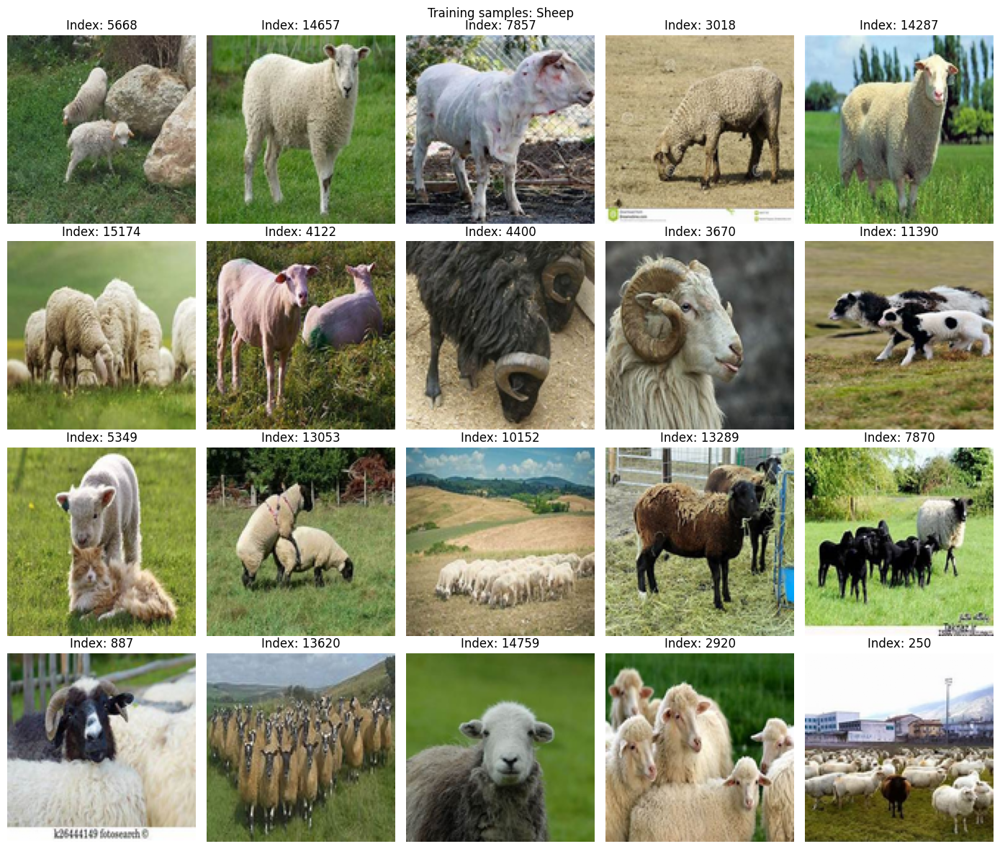

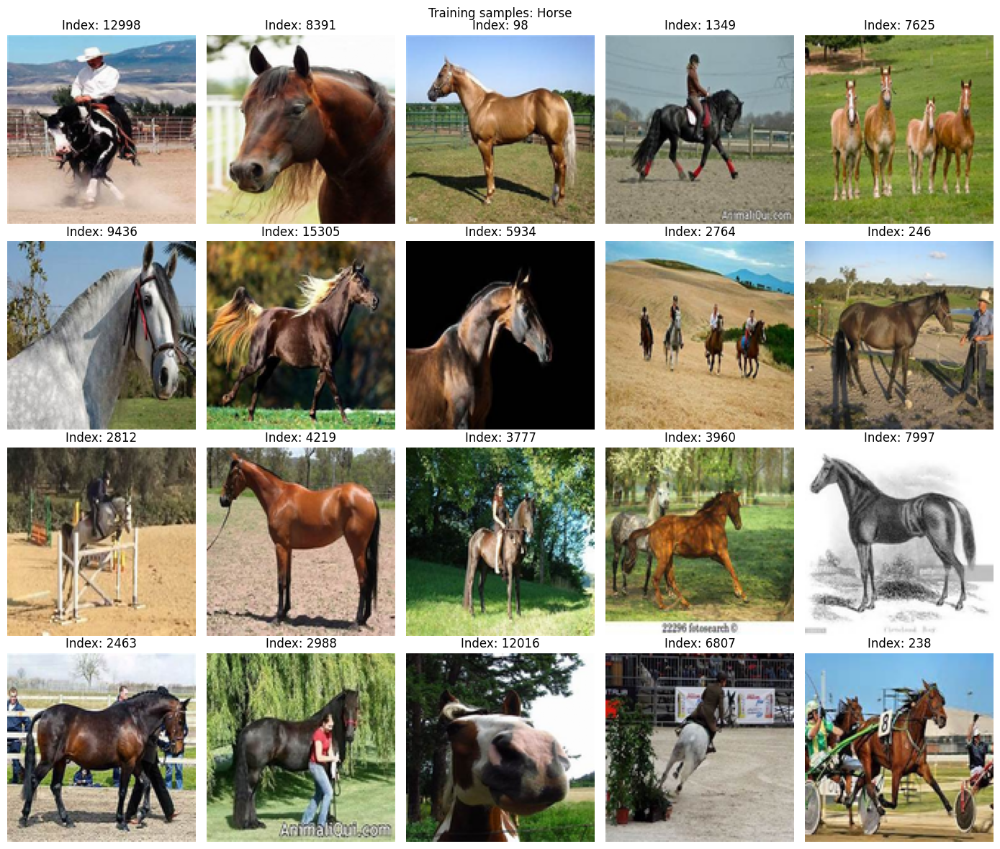

In [60]:
import numpy as np
import matplotlib.pyplot as plt

train_labels = np.asarray(y_train).reshape(-1)
rng = np.random.default_rng(123)

classes_to_review = {
    7: "Sheep",
    6: "Horse",
}

excluded_indices = {9706, 9556, 7224}

for class_id, class_name in classes_to_review.items():
    class_indices = np.flatnonzero(train_labels == class_id)
    class_indices = np.array(
        [i for i in class_indices if i not in excluded_indices]
    )

    selected_indices = rng.choice(
        class_indices,
        size=min(20, len(class_indices)),
        replace=False,
    )

    fig, axes = plt.subplots(4, 5, figsize=(14, 12))
    fig.suptitle(f"Training samples: {class_name}")

    for ax, image_index in zip(axes.flat, selected_indices):
        image = X_train[image_index].astype(np.float32) / PIXEL_SCALE
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(f"Index: {image_index}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [61]:
import numpy as np

class_names = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

indices_to_check = [11390, 4122, 12998, 12016]
train_labels = np.asarray(y_train).reshape(-1)

print("Image label and oversampling review:")
for image_index in indices_to_check:
    stored_label = int(train_labels[image_index])
    occurrences = int(np.count_nonzero(train_indices == image_index))

    print(
        f"Index {image_index}: "
        f"stored label = {class_names[stored_label]}, "
        f"occurrences per epoch = {occurrences}"
    )

Image label and oversampling review:
Index 11390: stored label = Sheep, occurrences per epoch = 1
Index 4122: stored label = Sheep, occurrences per epoch = 6
Index 12998: stored label = Horse, occurrences per epoch = 3
Index 12016: stored label = Horse, occurrences per epoch = 2


In [62]:
import numpy as np

clean_labels = np.asarray(y_train).copy()

known_mislabeled_indices = [9706, 4122]
unidentifiable_index = 12016

for image_index in known_mislabeled_indices:
    if int(clean_labels[image_index]) != 7:
        raise ValueError(
            f"Expected Sheep label 7 at index {image_index}, "
            f"found {int(clean_labels[image_index])}."
        )
    clean_labels[image_index] = 3

keep_mask = np.ones(len(clean_labels), dtype=bool)
keep_mask[unidentifiable_index] = False
kept_original_indices = np.flatnonzero(keep_mask)

clean_balanced_relative_indices = create_balanced_indices(
    clean_labels[kept_original_indices],
    random_state=42,
)
clean_balanced_original_indices = kept_original_indices[
    clean_balanced_relative_indices
]

print("Original training labels remain unchanged:")
print(f"Index 9706: {int(y_train[9706])}")
print(f"Index 4122: {int(y_train[4122])}")
print(f"Index 12016 included in clean training copy: {keep_mask[12016]}")

print("\nClean-copy class counts before oversampling:")
print(np.bincount(clean_labels[kept_original_indices], minlength=NUM_CLASSES))

print("\nClean-copy class counts after oversampling:")
print(
    np.bincount(
        clean_labels[clean_balanced_original_indices],
        minlength=NUM_CLASSES,
    )
)

Original training labels remain unchanged:
Index 9706: 7
Index 4122: 7
Index 12016 included in clean training copy: False

Clean-copy class counts before oversampling:
[1122  839 2095 1260 3368  726 1817  961 3038 1260]

Clean-copy class counts after oversampling:
[3368 3368 3368 3368 3368 3368 3368 3368 3368 3368]


In [63]:
from pathlib import Path
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

clean_train_dataset = make_dataset_from_indices(
    X_train,
    clean_labels,
    clean_balanced_original_indices,
    batch_size=32,
    training=True,
)

clean_model_path = Path(
    "/kaggle/working/models/animals10_clean_retrained_lr_0_0003.keras"
)

clean_model = build_cnn(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
)

clean_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clean_model_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=4,
    restore_best_weights=True,
    verbose=1,
)

clean_training_history = clean_model.fit(
    clean_train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if clean_model_path.is_file():
    best_clean_model = tf.keras.models.load_model(clean_model_path)
    clean_val_results = best_clean_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Clean retraining validation results:")
    for metric_name, metric_value in clean_val_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No clean retraining checkpoint was saved.")

Epoch 1/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1754 - loss: 2.2035
Epoch 1: val_loss improved from None to 2.09902, saving model to /kaggle/working/models/animals10_clean_retrained_lr_0_0003.keras

Epoch 1: finished saving model to /kaggle/working/models/animals10_clean_retrained_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.2242 - loss: 2.1209 - val_accuracy: 0.2021 - val_loss: 2.0990
Epoch 2/30
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3048 - loss: 1.9419
Epoch 2: val_loss improved from 2.09902 to 1.93242, saving model to /kaggle/working/models/animals10_clean_retrained_lr_0_0003.keras

Epoch 2: finished saving model to /kaggle/working/models/animals10_clean_retrained_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.3223 - loss: 1.9006 - val_accuracy: 0.2884 - val_loss: 1.9324
Epoch 3/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3594 - loss: 1.7978
Epoch 3: val_loss improved f

In [64]:
from pathlib import Path
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

clean_baseline_path = Path(
    "/kaggle/working/models/animals10_clean_baseline.keras"
)

clean_baseline_model = build_cnn(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
)

clean_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clean_baseline_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

clean_baseline_history = clean_baseline_model.fit(
    clean_train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[checkpoint_callback],
)

if clean_baseline_path.is_file():
    best_clean_baseline = tf.keras.models.load_model(clean_baseline_path)
    clean_baseline_results = best_clean_baseline.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Clean baseline validation results:")
    for metric_name, metric_value in clean_baseline_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No clean baseline checkpoint was saved.")

Epoch 1/10
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1834 - loss: 2.1845
Epoch 1: val_loss improved from None to 1.96432, saving model to /kaggle/working/models/animals10_clean_baseline.keras

Epoch 1: finished saving model to /kaggle/working/models/animals10_clean_baseline.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.2386 - loss: 2.0747 - val_accuracy: 0.2726 - val_loss: 1.9643
Epoch 2/10
1052/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3519 - loss: 1.7978
Epoch 2: val_loss improved from 1.96432 to 1.62772, saving model to /kaggle/working/models/animals10_clean_baseline.keras

Epoch 2: finished saving model to /kaggle/working/models/animals10_clean_baseline.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.3756 - loss: 1.7318 - val_accuracy: 0.4056 - val_loss: 1.6277
Epoch 3/10
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4266 - loss: 1.5834
Epoch 3: val_loss did not improve from 1.62772
1053/1053 ━━━━━━━━━━━━━━━

In [65]:
from pathlib import Path
import tensorflow as tf

clean_baseline_path = Path(
    "/kaggle/working/models/animals10_clean_baseline.keras"
)
clean_extended_path = Path(
    "/kaggle/working/models/animals10_clean_extended_lr_0_0003.keras"
)

if not clean_baseline_path.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {clean_baseline_path}"
    )

clean_extended_model = tf.keras.models.load_model(
    clean_baseline_path
)
clean_extended_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clean_extended_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

clean_extended_history = clean_extended_model.fit(
    clean_train_dataset,
    validation_data=val_dataset,
    initial_epoch=10,
    epochs=20,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if clean_extended_path.is_file():
    best_clean_extended_model = tf.keras.models.load_model(
        clean_extended_path
    )
    clean_extended_results = best_clean_extended_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Clean extended validation results:")
    for metric_name, metric_value in clean_extended_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No clean extended checkpoint was saved.")

Epoch 11/20
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6926 - loss: 0.8888
Epoch 11: val_loss improved from None to 1.04137, saving model to /kaggle/working/models/animals10_clean_extended_lr_0_0003.keras

Epoch 11: finished saving model to /kaggle/working/models/animals10_clean_extended_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - accuracy: 0.6957 - loss: 0.8775 - val_accuracy: 0.6235 - val_loss: 1.0414
Epoch 12/20
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6989 - loss: 0.8584
Epoch 12: val_loss improved from 1.04137 to 1.01234, saving model to /kaggle/working/models/animals10_clean_extended_lr_0_0003.keras

Epoch 12: finished saving model to /kaggle/working/models/animals10_clean_extended_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 24s 23ms/step - accuracy: 0.7025 - loss: 0.8533 - val_accuracy: 0.6436 - val_loss: 1.0123
Epoch 13/20
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7079 - loss: 0.8457
Epoch 13: val_loss improv

In [66]:
from pathlib import Path
import tensorflow as tf

source_path = Path(
    "/kaggle/working/models/animals10_clean_extended_lr_0_0003.keras"
)
continued_path = Path(
    "/kaggle/working/models/animals10_clean_continued_lr_0_0003.keras"
)

if not source_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {source_path}")

continued_clean_model = tf.keras.models.load_model(source_path)
continued_clean_model.optimizer.learning_rate.assign(0.0003)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(continued_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=4,
    restore_best_weights=True,
    verbose=1,
)

continued_clean_history = continued_clean_model.fit(
    clean_train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_callback, early_stopping_callback],
)

if continued_path.is_file():
    best_continued_clean_model = tf.keras.models.load_model(
        continued_path
    )
    continued_clean_results = best_continued_clean_model.evaluate(
        val_dataset,
        return_dict=True,
        verbose=0,
    )

    print("Continued clean training validation results:")
    for metric_name, metric_value in continued_clean_results.items():
        print(f"{metric_name}: {metric_value:.4f}")
else:
    print("No continued clean checkpoint was saved.")

Epoch 21/30
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7442 - loss: 0.7378
Epoch 21: val_loss improved from None to 0.96565, saving model to /kaggle/working/models/animals10_clean_continued_lr_0_0003.keras

Epoch 21: finished saving model to /kaggle/working/models/animals10_clean_continued_lr_0_0003.keras
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - accuracy: 0.7453 - loss: 0.7349 - val_accuracy: 0.6569 - val_loss: 0.9657
Epoch 22/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7511 - loss: 0.7262
Epoch 22: val_loss did not improve from 0.96565
1053/1053 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.7506 - loss: 0.7224 - val_accuracy: 0.6567 - val_loss: 0.9771
Epoch 23/30
1051/1053 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7537 - loss: 0.7111
Epoch 23: val_loss improved from 0.96565 to 0.94239, saving model to /kaggle/working/models/animals10_clean_continued_lr_0_0003.keras

Epoch 23: finished saving model to /kaggle/working/models/animals10_clean

In [67]:
import numpy as np
from sklearn.metrics import classification_report

clean_probabilities = best_continued_clean_model.predict(
    val_dataset,
    verbose=0,
)
clean_predictions = clean_probabilities.argmax(axis=1)
val_true_labels = np.asarray(y_val).reshape(-1)
class_ids = np.arange(NUM_CLASSES)

print("Clean model validation classification report:")
print(
    classification_report(
        val_true_labels,
        clean_predictions,
        labels=class_ids,
        digits=3,
        zero_division=0,
    )
)

Clean model validation classification report:
              precision    recall  f1-score   support

           0      0.800     0.767     0.783       240
           1      0.394     0.600     0.476       180
           2      0.802     0.855     0.828       449
           3      0.546     0.729     0.624       269
           4      0.772     0.470     0.584       721
           5      0.684     0.679     0.682       156
           6      0.683     0.669     0.676       390
           7      0.626     0.614     0.620       207
           8      0.836     0.851     0.843       651
           9      0.544     0.704     0.614       270

    accuracy                          0.693      3533
   macro avg      0.669     0.694     0.673      3533
weighted avg      0.713     0.693     0.693      3533



In [68]:
from pathlib import Path
from IPython.display import FileLink, display
import os

model_path = Path(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)

if model_path.is_file():
    print("Selected model checkpoint is ready.")
    display(FileLink(os.path.relpath(model_path)))
else:
    print(f"Model checkpoint not found: {model_path}")

Selected model checkpoint is ready.


/kaggle/working/models/animals10_trial_lr_0_0003.keras

In [70]:
try:
    import gradio as gr
    print(f"Gradio is installed: {gr.__version__}")
except ImportError:
    print("Gradio is not installed.")

Gradio is installed: 6.30.0


In [72]:
import io

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display
from PIL import Image

model = tf.keras.models.load_model(
    "/kaggle/working/models/animals10_trial_lr_0_0003.keras"
)

# ضيف أسماء الحيوانات هنا باستخدام ترتيب الـlabels الحقيقي من فريق الداتا.
# مثال فقط: CLASS_NAMES = {0: "اسم الحيوان صاحب الـID 0"}
CLASS_NAMES = {
    0: "Butterfly",
    1: "Cat",
    2: "Chicken",
    3: "Cow",
    4: "Dog",
    5: "Elephant",
    6: "Horse",
    7: "Sheep",
    8: "Spider",
    9: "Squirrel",
}

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload image",
)
output = widgets.Output()

def predict_uploaded_image(change):
    files = change["new"]
    if not files:
        return

    # دعم شكل الملف في الإصدارات المختلفة من ipywidgets
    uploaded_file = next(iter(files.values())) if isinstance(files, dict) else files[0]

    with output:
        output.clear_output(wait=True)

        with Image.open(io.BytesIO(bytes(uploaded_file["content"]))) as image_file:
            image = image_file.convert("RGB")

        height, width = model.input_shape[1:3]
        resized = image.resize((width, height), Image.Resampling.BILINEAR)
        pixels = np.asarray(resized, dtype=np.float32) / 255.0

        scores = model.predict(pixels[None, ...], verbose=0)[0]
        top_ids = np.argsort(scores)[-3:][::-1]

        plt.imshow(image)
        plt.axis("off")
        plt.show()

        print("Top 3 predictions")
        for class_id in top_ids:
            name = CLASS_NAMES.get(int(class_id), f"Class {class_id}")
            print(f"{name}: {scores[class_id]:.1%}")

upload.observe(predict_uploaded_image, names="value")
display(upload, output)

FileUpload(value=(), accept='image/*', description='Upload image')

Output()